# Vehicle Classification with ResNet50 and MaxViT-Tiny (Transfer Learning)
## Class balancing + Albumentations augmentation, compared across a CNN and a Vision Transformer

**Goal.** Fine-tune two ImageNet-pretrained models on the vehicle dataset, then measure whether
**class balancing + Albumentations augmentation** reduces misclassifications.

| Model | Type | Pretrained source |
|-------|------|-------------------|
| ResNet50 | CNN | torchvision ImageNet weights |
| MaxViT-Tiny (`maxvit_t`) | CNN + Transformer hybrid | torchvision ImageNet weights |

### Experiments (run for each model)

| ID | Experiment | Class balancing | Augmentation | Role |
|----|-----------|-----------------|--------------|------|
| A | `A_no_aug_imbalanced` | none | none | Reference: effect of imbalance |
| B | `B_no_aug_balanced` | balanced sampler | none | **BEFORE** augmentation |
| C | `C_aug_balanced` | balanced sampler | Albumentations | **AFTER** augmentation |

B and C differ **only** in augmentation.

### Contents
1. Setup  2. Transfer-learning guard  3. Data  4. Augmentation  5. Balancing  6. Models and training
7. Run experiments  8. Results  9. Before/after misclassification analysis  10. Verdict and export

> **Kaggle checklist:** Accelerator = GPU (T4 / P100) · dataset attached · ImageNet weights for ResNet50 and MaxViT-Tiny
> available (attach them as Input, or turn Internet ON). See section 2.

---
## 1. Setup and configuration
All settings are in this one cell.

In [1]:
# =====================================================================
# 1. IMPORTS & CONFIGURATION
# =====================================================================
!pip install albumentations safetensors
!pip install torch torchvision albumentations scikit-learn scipy pandas numpy matplotlib seaborn pillow safetensors
import os, json, random, time, zipfile, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models

try:
    import albumentations as A
    from albumentations.pytorch import ToTensorV2
except ImportError as error:
    raise ImportError("albumentations is missing. Turn Internet ON and run: !pip install albumentations") from error

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             precision_recall_fscore_support, confusion_matrix, classification_report)
from scipy.stats import binomtest
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- paths ----------------
DATA_ROOT = "/kaggle/input/datasets/muhammadghulamabbas/vehicle/hj3vvx5946-1/Splited_dataset"
ON_KAGGLE = Path("/kaggle/working").is_dir()
WORK = Path("/kaggle/working") if ON_KAGGLE else Path("outputs")
WORK.mkdir(parents=True, exist_ok=True)
SEARCH_ROOTS = ["/kaggle/input", "."]                                     # where to look for the dataset
WEIGHT_SEARCH_ROOTS = ["/kaggle/input", os.path.expanduser("~/.cache/torch"), "."]
WEIGHT_HINTS = {"resnet50": "", "maxvit_t": ""}                           # optional: exact path to a .pth file

# ---------------- what to run ----------------
ARCHS = ["resnet50", "maxvit_t"]
RESUME = True            # skip runs whose results are already saved in WORK (set False to retrain everything)

# ---------------- reproducibility / data ----------------
SEED = 42
IMAGE_SIZE = 224         # MaxViT-Tiny needs 224 (feature map must divide by its window size 7)
BATCH_SIZE = 32          # lower to 16 if MaxViT runs out of GPU memory
NUM_WORKERS = 2
VAL_FRACTION = 0.15
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet statistics (both models)

# ---------------- training (shared) ----------------
DROPOUT = 0.3
STAGE1_EPOCHS = 5        # stage 1: new head only (backbone frozen)
STAGE2_EPOCHS = 15       # stage 2: head + upper backbone stages, early stopping
LABEL_SMOOTHING = 0.1
PATIENCE = 4
CLIP_NORM = 1.0

# ---------------- training (per model) ----------------
HP = {
    "resnet50": dict(lr_stage1=1e-3, lr_backbone=1e-4, lr_head=5e-4, weight_decay=1e-4),
    "maxvit_t": dict(lr_stage1=5e-4, lr_backbone=5e-5, lr_head=5e-4, weight_decay=1e-2),   # transformers: smaller LR, larger decay
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print(f"device={DEVICE} | torch={torch.__version__} | albumentations={A.__version__}")
if DEVICE.type == "cpu":
    print("WARNING: no GPU detected. Enable it in Kaggle: Session options -> Accelerator -> GPU.")

/usr/local/lib/python3.13/dist-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error [Errno -3] Temporary failure in name resolution>
  data = fetch_version_info()


device=cuda | torch=2.11.0+cu128 | albumentations=2.0.8


---
## 2. Transfer-learning guard
Training from scratch would ruin the comparison, so this notebook **refuses to continue without real ImageNet weights**.

For each model, a weights file is accepted only if it loads into the matching torchvision architecture with
`strict=True` (every tensor present, including the 1000-class ImageNet head). Search order:

1. the path in `WEIGHT_HINTS` (if you set one)
2. any `.pth / .pt / .safetensors` under `/kaggle/input` (files whose path mentions the model are tried first)
3. a torchvision download (works only when Internet is ON)

If a model has no valid weights, the cell stops with instructions and no training starts.

**If Internet is OFF on Kaggle**, create the weight files once somewhere with Internet (Colab or your PC) and upload them
as a Kaggle Dataset or Model:
```python
import torch
from torchvision import models
torch.save(models.resnet50(weights="DEFAULT").state_dict(), "resnet50_imagenet.pth")
torch.save(models.maxvit_t(weights="DEFAULT").state_dict(), "maxvit_t_imagenet.pth")
```
Then **Add Input** to this notebook and re-run. (timm-format files will be rejected by the strict check; use the torchvision ones.)

In [2]:
# =====================================================================
# 2. TRANSFER-LEARNING GUARD: locate and verify ImageNet weights
# =====================================================================
ARCH_INFO = {
    "resnet50": dict(
        title="ResNet50", ctor=models.resnet50, enum="ResNet50_Weights",
        keywords=("resnet50", "resnet-50", "resnet_50"),
        frozen=("conv1.", "bn1.", "layer1.", "layer2."),          # kept identical to ImageNet in stage 2
        tuned=("layer3.", "layer4."),                              # fine-tuned in stage 2
        stage2_text="layer3 + layer4 + new fc"),
    "maxvit_t": dict(
        title="MaxViT-Tiny", ctor=models.maxvit_t, enum="MaxVit_T_Weights",
        keywords=("maxvit",),
        frozen=("stem.", "blocks.0.", "blocks.1."),
        tuned=("blocks.2.", "blocks.3."),
        stage2_text="stages 3-4 (blocks.2, blocks.3) + new classifier"),
}

_STATE_CACHE = {}

def read_state_file(path):
    """Read a weights file and return a plain state_dict."""
    path = str(path)
    if path in _STATE_CACHE:
        return _STATE_CACHE[path]
    if path.lower().endswith(".safetensors"):
        from safetensors.torch import load_file
        state = load_file(path)
    else:
        try:
            state = torch.load(path, map_location="cpu", weights_only=True)
        except Exception:
            state = torch.load(path, map_location="cpu", weights_only=False)
    if isinstance(state, dict):
        for key in ("state_dict", "model_state_dict", "model"):
            if key in state and isinstance(state[key], dict):
                state = state[key]
                break
    else:
        state = state.state_dict()
    state = {k.replace("module.", "", 1): v for k, v in state.items()}
    _STATE_CACHE[path] = state
    return state


def verify_imagenet_state(arch, state):
    """True only if `state` fits the torchvision architecture exactly (incl. 1000-class head)."""
    try:
        ARCH_INFO[arch]["ctor"](weights=None).load_state_dict(state, strict=True)
        return True, "ok"
    except Exception as error:
        return False, f"{type(error).__name__}: {str(error)[:100]}"


def candidate_weight_files(arch):
    hint = WEIGHT_HINTS.get(arch, "")
    files = [hint] if hint and os.path.exists(hint) else []
    keywords = ARCH_INFO[arch]["keywords"]
    found = []
    for root in WEIGHT_SEARCH_ROOTS:
        if not os.path.isdir(root):
            continue
        for dirpath, _, names in os.walk(root):
            for name in names:
                full = os.path.join(dirpath, name)
                if (name.lower().endswith((".pth", ".pt", ".safetensors"))
                        and not name.startswith(("best_", "vehicle_"))       # skip our own checkpoints
                        and full not in files and full not in found
                        and os.path.getsize(full) < 600e6):
                    found.append(full)
    found.sort(key=lambda p: not any(k in p.lower() for k in keywords))    # model-named files first
    return files + found


def locate_pretrained_state(arch):
    info = ARCH_INFO[arch]
    for path in candidate_weight_files(arch):
        try:
            state = read_state_file(path)
        except Exception:
            continue
        ok, message = verify_imagenet_state(arch, state)
        if ok:
            return state, f"local file: {path}"
        if any(k in path.lower() for k in info["keywords"]):
            print(f"  [{arch}] skip {path}: {message}")
    try:                                                          # last resort: Internet
        state = getattr(models, info["enum"]).DEFAULT.get_state_dict(progress=True)
        if verify_imagenet_state(arch, state)[0]:
            return state, "torchvision download (Internet)"
    except Exception as error:
        print(f"  [{arch}] download not possible: {type(error).__name__}")
    return None, None


PRETRAINED, missing = {}, []
for arch in ARCHS:
    state, source = locate_pretrained_state(arch)
    if state is None:
        missing.append(arch)
    else:
        PRETRAINED[arch] = (state, source)

if missing:
    raise RuntimeError(
        f"\n\nNO PRETRAINED WEIGHTS FOUND for: {', '.join(missing)}  -> transfer learning is impossible, training is blocked.\n"
        "Fix with ONE of:\n"
        "  A) Session options -> Internet = ON (phone-verified account) -> re-run.\n"
        "  B) Create the .pth files with the snippet in the markdown above, upload them as a Kaggle Dataset/Model,\n"
        "     Add Input to this notebook, re-run.\n")

print("=" * 78)
print("TRANSFER LEARNING: ENABLED")
for arch, (state, source) in PRETRAINED.items():
    print(f"  {ARCH_INFO[arch]['title']:12s}: {len(state)} tensors, {sum(v.numel() for v in state.values()):,} params | {source}")
print("=" * 78)

TRANSFER LEARNING: ENABLED
  ResNet50    : 320 tensors, 25,610,205 params | local file: /kaggle/input/models/muhammadghulamabbas/resnet50-imagenet/pytorch/default/1/resnet50-11ad3fa6.pth
  MaxViT-Tiny : 582 tensors, 31,020,096 params | local file: /kaggle/input/models/muhammadghulamabbas/maxvit-t-imagenet/pytorch/default/1/maxvit_t-bc5ab103.pth


---
## 3. Data loading and class distribution
The dataset has `train/` and `test/` folders (one sub-folder per class). A **stratified 15 % validation split** is taken
from `train/` for early stopping and checkpoint selection, so the **test set is never used for any training decision**.

classes: 48 | train: 2631 | val: 465 | test: 751
imbalance ratio (largest / smallest class): 20.8x


,class_name,train,val,test
0,Toyota_corolla_2016,229,41,67
1,Suzuki_cultus_2018,229,40,67
2,Suzuki_Mehran,166,29,48
3,Suzuki_alto_2007,112,20,32
4,Toyota_corolla_2011,108,19,31
5,Suzuki_swift,100,18,29
6,Suzuki_wagonR_2015,95,17,27
7,Suzuki_cultus_2019,92,16,27
8,Honda_City_aspire,89,16,26
9,Honda_civic_2018,70,12,20


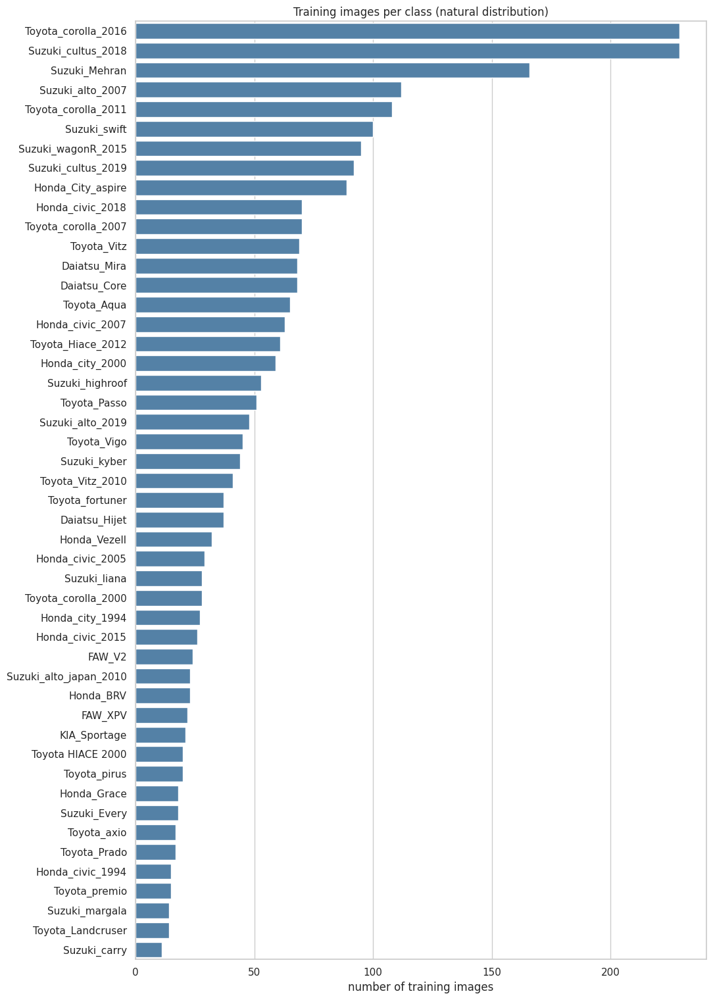

In [3]:
# =====================================================================
# 3. DATA LOADING
# =====================================================================
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def worker_init_fn(worker_id):
    np.random.seed(SEED + worker_id); random.seed(SEED + worker_id)


def make_generator(seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)
    return g


def find_split_dir(data_root):
    path = Path(data_root)
    if path.name == "Splited_dataset" and path.is_dir():
        return path
    if (path / "Splited_dataset").is_dir():
        return path / "Splited_dataset"
    for base in SEARCH_ROOTS:
        for dirpath, dirnames, _ in os.walk(base):
            if "Splited_dataset" in dirnames:
                return Path(dirpath) / "Splited_dataset"
    raise FileNotFoundError("Splited_dataset folder not found. Attach the dataset via Add Input.")


def is_valid_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False


def scan_split(split_dir):
    class_names = sorted(d.name for d in split_dir.iterdir() if d.is_dir() and not d.name.startswith("."))
    paths, labels = [], []
    for idx, name in enumerate(class_names):
        for f in sorted((split_dir / name).iterdir()):
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS and is_valid_image(f):
                paths.append(str(f)); labels.append(idx)
    return class_names, np.array(paths), np.array(labels)


def prepare_data():
    root = find_split_dir(DATA_ROOT)
    class_names, paths, labels = scan_split(root / "train")
    test_classes, test_paths, test_labels = scan_split(root / "test")
    assert class_names == test_classes, "train/test class folders differ"
    train_idx, val_idx = train_test_split(np.arange(len(paths)), test_size=VAL_FRACTION,
                                          stratify=labels, random_state=SEED)
    assert not set(paths[train_idx]) & set(paths[val_idx]), "train/val leakage"
    return dict(root=root, class_names=class_names, paths=paths, labels=labels,
                train_idx=train_idx, val_idx=val_idx, test_paths=test_paths, test_labels=test_labels)


DATA = prepare_data()
CLASS_NAMES = DATA["class_names"]
N_CLASSES = len(CLASS_NAMES)
TRAIN_COUNTS = np.bincount(DATA["labels"][DATA["train_idx"]], minlength=N_CLASSES)

counts_df = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "train": TRAIN_COUNTS,
    "val": np.bincount(DATA["labels"][DATA["val_idx"]], minlength=N_CLASSES),
    "test": np.bincount(DATA["test_labels"], minlength=N_CLASSES),
}).sort_values("train", ascending=False).reset_index(drop=True)

print(f"classes: {N_CLASSES} | train: {len(DATA['train_idx'])} | val: {len(DATA['val_idx'])} | test: {len(DATA['test_paths'])}")
print(f"imbalance ratio (largest / smallest class): {TRAIN_COUNTS.max() / TRAIN_COUNTS.min():.1f}x")
display(counts_df)

fig, ax = plt.subplots(figsize=(11, max(4, 0.32 * N_CLASSES)))
sns.barplot(data=counts_df, y="class_name", x="train", color="steelblue", ax=ax)
ax.set_title("Training images per class (natural distribution)")
ax.set_xlabel("number of training images"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(WORK / "01_class_distribution.png", dpi=150); plt.show()

---
## 4. Albumentations pipelines
| Level | Used for | Operations |
|-------|----------|-----------|
| `none` | validation, test, and the **BEFORE** experiments | resize + normalize only |
| `standard` | majority classes in the **AFTER** experiment | flip, mild affine, brightness/contrast, small hue shift |
| `strong` | **minority classes** (fewer images than the median class) | the above, stronger, plus blur and rare grayscale |

Hue shifts are kept tiny so vehicle colour is preserved.

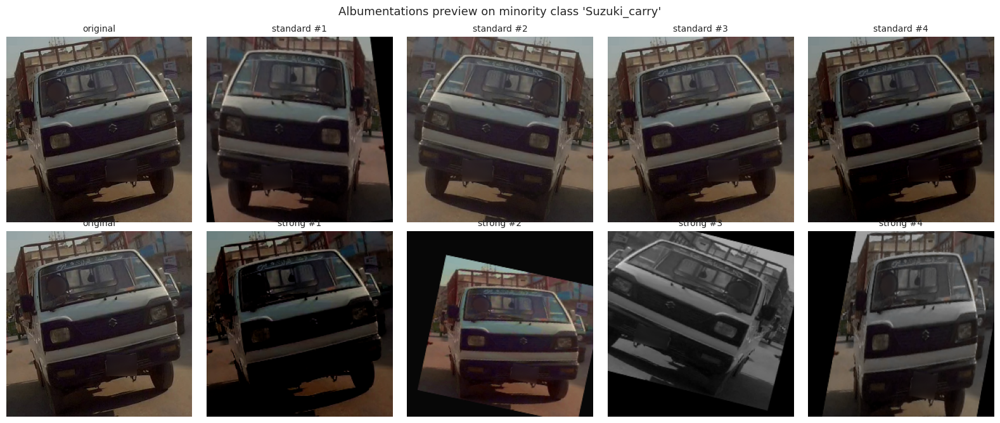

In [4]:
# =====================================================================
# 4. ALBUMENTATIONS PIPELINES + DATASET
# =====================================================================
def build_pipeline(level):
    resize = [A.Resize(IMAGE_SIZE, IMAGE_SIZE)]
    tail = [A.Normalize(mean=MEAN, std=STD), ToTensorV2()]
    if level == "none":
        ops = []
    elif level == "standard":
        ops = [
            A.HorizontalFlip(p=0.5),
            A.Affine(scale=(0.85, 1.15), translate_percent=(-0.06, 0.06), rotate=(-10, 10), p=0.6),
            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
            A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=10, p=0.3),
        ]
    elif level == "strong":
        ops = [
            A.HorizontalFlip(p=0.5),
            A.Affine(scale=(0.70, 1.25), translate_percent=(-0.10, 0.10), rotate=(-15, 15), p=0.8),
            A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.7),
            A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=25, val_shift_limit=15, p=0.5),
            A.OneOf([A.GaussianBlur(blur_limit=(3, 5)), A.MotionBlur(blur_limit=5)], p=0.3),
            A.ToGray(p=0.05),
        ]
    else:
        raise ValueError(level)
    return A.Compose(resize + ops + tail)


PIPELINES = {lvl: build_pipeline(lvl) for lvl in ("none", "standard", "strong")}


def make_class_policy(augmentation):
    """Map every class index -> augmentation level."""
    if augmentation == "none":
        return {c: "none" for c in range(N_CLASSES)}
    median = np.median(TRAIN_COUNTS)
    return {c: ("strong" if TRAIN_COUNTS[c] < median else "standard") for c in range(N_CLASSES)}


class VehicleDataset(Dataset):
    def __init__(self, paths, labels, indices, policy):
        self.paths, self.labels = paths, labels
        self.indices = np.asarray(indices)
        self.policy = policy

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        label = int(self.labels[j])
        with Image.open(self.paths[j]) as im:
            image = np.array(im.convert("RGB"))
        return PIPELINES[self.policy[label]](image=image)["image"], label


# ---- preview: one minority-class image, original vs augmented ----
smallest = int(np.argmin(TRAIN_COUNTS))
sample_path = DATA["paths"][DATA["train_idx"]][DATA["labels"][DATA["train_idx"]] == smallest][0]
original = np.array(Image.open(sample_path).convert("RGB"))
preview = {lvl: A.Compose([t for t in PIPELINES[lvl].transforms if not isinstance(t, (A.Normalize, ToTensorV2))])
           for lvl in ("standard", "strong")}

fig, axes = plt.subplots(2, 5, figsize=(16, 6.8))
for r, lvl in enumerate(("standard", "strong")):
    axes[r, 0].imshow(original); axes[r, 0].set_title("original", fontsize=10)
    for c in range(1, 5):
        axes[r, c].imshow(preview[lvl](image=original)["image"]); axes[r, c].set_title(f"{lvl} #{c}", fontsize=10)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(f"Albumentations preview on minority class '{CLASS_NAMES[smallest]}'", fontsize=13)
fig.tight_layout(); fig.savefig(WORK / "02_augmentation_preview.png", dpi=150); plt.show()

---
## 5. Class balancing
A `WeightedRandomSampler` gives each training image the weight `1 / (images in its class)`, so every class is drawn with
equal probability. The next cell **proves** it by drawing one epoch and counting images per class.

Imbalance ratio  natural :   20.8x   |   balanced :  1.84x
Coefficient of variation natural : 0.89   |   balanced : 0.13   (0 = perfectly balanced)


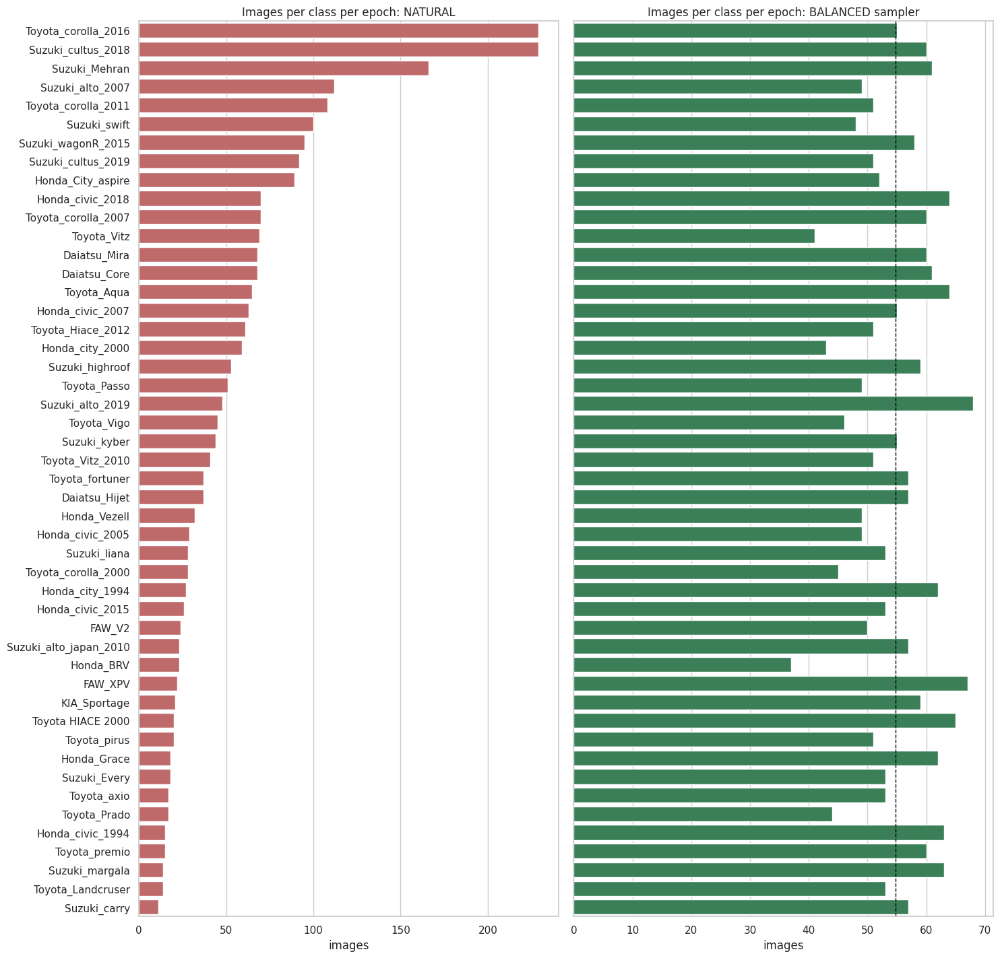

In [5]:
# =====================================================================
# 5. CLASS BALANCING (+ verification)
# =====================================================================
TRAIN_LABELS = DATA["labels"][DATA["train_idx"]]

def make_balanced_sampler(seed=SEED):
    weights = 1.0 / TRAIN_COUNTS[TRAIN_LABELS]
    return WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double),
                                 num_samples=len(TRAIN_LABELS), replacement=True, generator=make_generator(seed))

drawn = np.fromiter(iter(make_balanced_sampler()), dtype=int)
balanced_counts = np.bincount(TRAIN_LABELS[drawn], minlength=N_CLASSES)

check = pd.DataFrame({"class_name": CLASS_NAMES, "natural_per_epoch": TRAIN_COUNTS,
                      "balanced_per_epoch": balanced_counts}).sort_values("natural_per_epoch", ascending=False)
cv = lambda x: x.std() / x.mean()
print(f"Imbalance ratio  natural : {TRAIN_COUNTS.max() / TRAIN_COUNTS.min():6.1f}x   |   balanced : {balanced_counts.max() / max(balanced_counts.min(), 1):5.2f}x")
print(f"Coefficient of variation natural : {cv(TRAIN_COUNTS):.2f}   |   balanced : {cv(balanced_counts):.2f}   (0 = perfectly balanced)")

fig, axes = plt.subplots(1, 2, figsize=(15, max(4, 0.3 * N_CLASSES)), sharey=True)
sns.barplot(data=check, y="class_name", x="natural_per_epoch", color="indianred", ax=axes[0])
axes[0].set_title("Images per class per epoch: NATURAL")
sns.barplot(data=check, y="class_name", x="balanced_per_epoch", color="seagreen", ax=axes[1])
axes[1].set_title("Images per class per epoch: BALANCED sampler")
for ax in axes:
    ax.set_xlabel("images"); ax.set_ylabel("")
axes[1].axvline(len(TRAIN_LABELS) / N_CLASSES, ls="--", c="black", lw=1)
fig.tight_layout(); fig.savefig(WORK / "03_balancing_check.png", dpi=150); plt.show()

---
## 6. Models and training engine

**Two-stage transfer learning (same recipe for both models)**

| Stage | ResNet50 trainable | MaxViT-Tiny trainable | Purpose |
|-------|--------------------|-----------------------|---------|
| 1 (5 epochs) | new `fc` head only | new `classifier` head only | Align the new head with pretrained features |
| 2 (up to 15 epochs, early stopping) | head + `layer3`, `layer4` | head + stages 3-4 (`blocks.2`, `blocks.3`) | Adapt upper ImageNet features to vehicles |

Frozen layers also stay in `eval()` mode (BatchNorm statistics fixed). The best epoch is chosen by **validation macro-F1**.
After training, `verify_transfer` proves the frozen layers are **bit-identical** to the ImageNet weights and that the
fine-tuned layers have moved, i.e. the pretrained backbone was really used.

In [6]:
# =====================================================================
# 6. MODELS + TRAINING ENGINE
# =====================================================================
def build_model(arch, n_classes):
    """torchvision model with ImageNet weights and a new classification head (transfer learning)."""
    state = PRETRAINED[arch][0]
    model = ARCH_INFO[arch]["ctor"](weights=None)
    model.load_state_dict(state, strict=True)                          # <- the pretrained weights
    if arch == "resnet50":
        model.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(model.fc.in_features, n_classes))
    else:                                                              # maxvit_t: replace the final Linear (index 5)
        last = model.classifier[5]
        model.classifier[5] = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(last.in_features, n_classes))
    first = next(iter(state))                                          # hard check: backbone holds pretrained tensors
    assert torch.equal(model.state_dict()[first].cpu(), state[first].cpu()), "pretrained weights were not applied"
    return model


def head_module(arch, model):
    return model.fc if arch == "resnet50" else model.classifier


def upper_modules(arch, model):
    return [model.layer3, model.layer4] if arch == "resnet50" else [model.blocks[2], model.blocks[3]]


def stage_modules(arch, model, stage):
    head = head_module(arch, model)
    return [head] if stage == 1 else [head] + upper_modules(arch, model)


def verify_transfer(arch, model):
    """Frozen layers must equal ImageNet weights; fine-tuned layers should have moved."""
    info, ref, sd = ARCH_INFO[arch], PRETRAINED[arch][0], model.state_dict()
    frozen_same = all(torch.equal(sd[k].cpu(), ref[k].cpu()) for k in ref if k.startswith(info["frozen"]))
    tuned = [k for k in ref if k.startswith(info["tuned"]) and ref[k].dtype.is_floating_point]
    moved = float(np.mean([not torch.equal(sd[k].cpu(), ref[k].cpu()) for k in tuned]))
    return frozen_same, moved


def set_trainable(model, modules):
    for p in model.parameters():
        p.requires_grad = False
    for m in modules:
        for p in m.parameters():
            p.requires_grad = True


def set_train_mode(model, modules):
    model.eval()                       # frozen layers keep fixed BatchNorm statistics / no stochastic depth
    for m in modules:
        m.train()


def compute_metrics(y_true, y_pred, prefix):
    labels = np.arange(N_CLASSES)
    return {
        f"{prefix}_acc": float(accuracy_score(y_true, y_pred)),
        f"{prefix}_balanced_acc": float(balanced_accuracy_score(y_true, y_pred)),
        f"{prefix}_macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        f"{prefix}_weighted_f1": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        f"{prefix}_macro_precision": float(precision_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        f"{prefix}_macro_recall": float(recall_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
    }


def train_one_epoch(model, loader, criterion, optimizer, scaler, modules):
    set_train_mode(model, modules)
    params = [p for p in model.parameters() if p.requires_grad]
    total, seen = 0.0, 0
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            loss = criterion(model(images), targets)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(params, CLIP_NORM)
        scaler.step(optimizer); scaler.update()
        total += loss.item() * targets.size(0); seen += targets.size(0)
    return total / seen


@torch.no_grad()
def predict(model, loader, criterion):
    model.eval()
    total, seen, preds, truths = 0.0, 0, [], []
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            out = model(images)
            loss = criterion(out, targets)
        total += loss.item() * targets.size(0); seen += targets.size(0)
        preds.append(out.argmax(1).cpu().numpy()); truths.append(targets.cpu().numpy())
    return total / seen, np.concatenate(preds), np.concatenate(truths)


def fit_stage(model, stage, epochs, optimizer, scheduler, modules, loaders, criterion, state, patience=None):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    stale = 0
    for _ in range(epochs):
        lr = optimizer.param_groups[0]["lr"]
        train_loss = train_one_epoch(model, loaders["train"], criterion, optimizer, scaler, modules)
        val_loss, vp, vt = predict(model, loaders["val"], criterion)
        vm = compute_metrics(vt, vp, "val")
        if scheduler is not None:
            scheduler.step()
        state["step"] += 1
        state["history"].append(dict(epoch=state["step"], stage=stage, lr=lr, train_loss=train_loss, val_loss=val_loss, **vm))
        improved = vm["val_macro_f1"] > state["best_f1"]
        if improved:
            state["best_f1"] = vm["val_macro_f1"]
            torch.save(model.state_dict(), state["checkpoint"])
            stale = 0
        else:
            stale += 1
        print(f"  [stage {stage}] epoch {state['step']:02d} | lr {lr:.1e} | train {train_loss:.4f} | "
              f"val {val_loss:.4f} | val acc {vm['val_acc']:.4f} | val macro-F1 {vm['val_macro_f1']:.4f}"
              f"{'  *best*' if improved else ''}")
        if patience is not None and stale >= patience:
            print(f"  early stopping (no improvement for {patience} epochs)")
            break

---
## 7. Run experiments
For each model, A, B and C start from the **same seed and the same pretrained weights**. Curves, confusion matrices,
reports and per-class CSVs go to the output folder. With `RESUME = True`, finished runs are loaded from disk instead of
being retrained, so a crash or restart does not lose completed work.

Six trainings in total (2 models x 3 experiments). MaxViT-Tiny is the slower one.


ResNet50  |  A_no_aug_imbalanced  |  balance=False  augmentation=none
  stage 1: head only (98,352 trainable params)
  [stage 1] epoch 01 | lr 1.0e-03 | train 3.4711 | val 3.2345 | val acc 0.2344 | val macro-F1 0.0443  *best*
  [stage 1] epoch 02 | lr 1.0e-03 | train 3.0124 | val 2.9573 | val acc 0.2688 | val macro-F1 0.0759  *best*
  [stage 1] epoch 03 | lr 1.0e-03 | train 2.7074 | val 2.7738 | val acc 0.3204 | val macro-F1 0.1280  *best*
  [stage 1] epoch 04 | lr 1.0e-03 | train 2.4755 | val 2.6176 | val acc 0.4065 | val macro-F1 0.2534  *best*
  [stage 1] epoch 05 | lr 1.0e-03 | train 2.2841 | val 2.4997 | val acc 0.4710 | val macro-F1 0.2769  *best*
  stage 2: fine-tuning layer3 + layer4 + new fc (22,161,456 trainable params)
  [stage 2] epoch 06 | lr 1.0e-04 | train 1.9236 | val 1.4343 | val acc 0.8129 | val macro-F1 0.7238  *best*
  [stage 2] epoch 07 | lr 9.9e-05 | train 0.9617 | val 1.2451 | val acc 0.8516 | val macro-F1 0.8050  *best*
  [stage 2] epoch 08 | lr 9.6e-05 | train

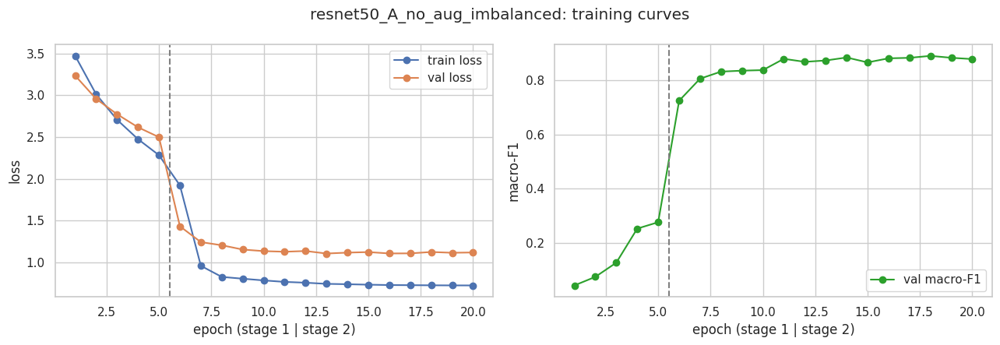

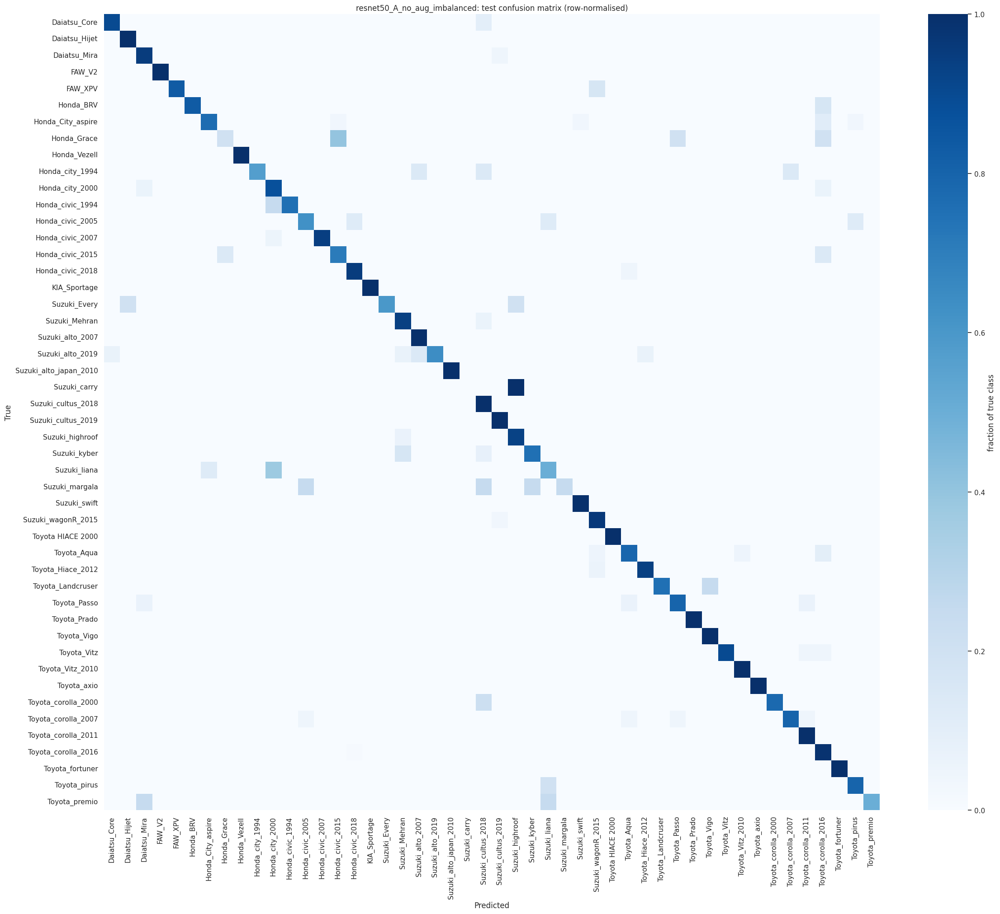


ResNet50  |  B_no_aug_balanced  |  balance=True  augmentation=none
  stage 1: head only (98,352 trainable params)
  [stage 1] epoch 01 | lr 1.0e-03 | train 3.5697 | val 3.4386 | val acc 0.2409 | val macro-F1 0.1884  *best*
  [stage 1] epoch 02 | lr 1.0e-03 | train 3.0249 | val 3.1598 | val acc 0.3570 | val macro-F1 0.3003  *best*
  [stage 1] epoch 03 | lr 1.0e-03 | train 2.6483 | val 2.9659 | val acc 0.4065 | val macro-F1 0.3702  *best*
  [stage 1] epoch 04 | lr 1.0e-03 | train 2.4007 | val 2.8065 | val acc 0.4688 | val macro-F1 0.4351  *best*
  [stage 1] epoch 05 | lr 1.0e-03 | train 2.1344 | val 2.6914 | val acc 0.4925 | val macro-F1 0.4726  *best*
  stage 2: fine-tuning layer3 + layer4 + new fc (22,161,456 trainable params)
  [stage 2] epoch 06 | lr 1.0e-04 | train 1.7358 | val 1.6606 | val acc 0.7290 | val macro-F1 0.6651  *best*
  [stage 2] epoch 07 | lr 9.9e-05 | train 0.9923 | val 1.3482 | val acc 0.8387 | val macro-F1 0.7796  *best*
  [stage 2] epoch 08 | lr 9.6e-05 | train 0.

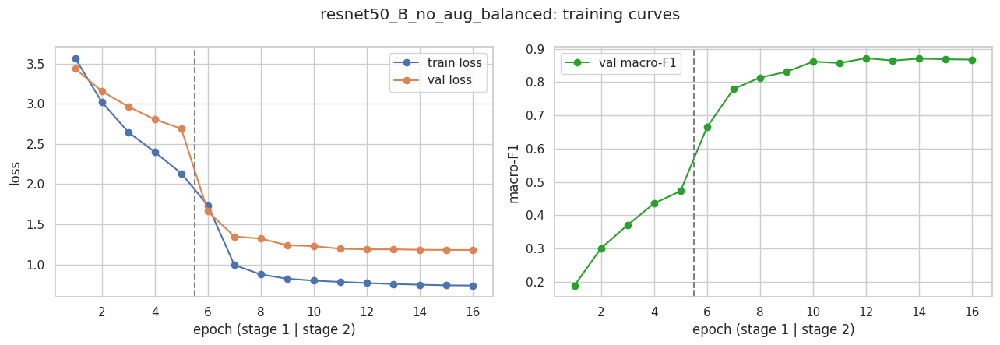

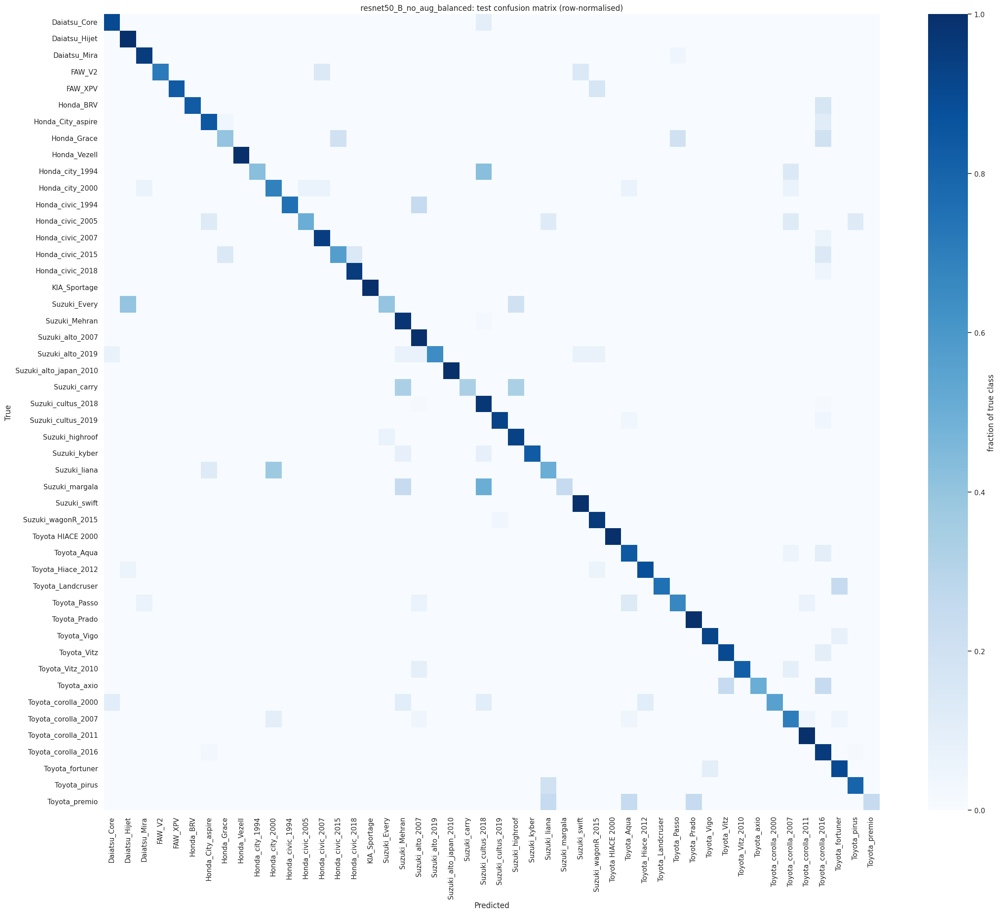


ResNet50  |  C_aug_balanced  |  balance=True  augmentation=albumentations
  augmentation levels per class: {'standard': 24, 'strong': 24}
  stage 1: head only (98,352 trainable params)
  [stage 1] epoch 01 | lr 1.0e-03 | train 3.6074 | val 3.4138 | val acc 0.3140 | val macro-F1 0.2199  *best*
  [stage 1] epoch 02 | lr 1.0e-03 | train 3.1633 | val 3.1283 | val acc 0.3935 | val macro-F1 0.3169  *best*
  [stage 1] epoch 03 | lr 1.0e-03 | train 2.8691 | val 2.9455 | val acc 0.4344 | val macro-F1 0.3802  *best*
  [stage 1] epoch 04 | lr 1.0e-03 | train 2.7009 | val 2.8119 | val acc 0.4968 | val macro-F1 0.4234  *best*
  [stage 1] epoch 05 | lr 1.0e-03 | train 2.4841 | val 2.7033 | val acc 0.4731 | val macro-F1 0.4188
  stage 2: fine-tuning layer3 + layer4 + new fc (22,161,456 trainable params)
  [stage 2] epoch 06 | lr 1.0e-04 | train 1.9969 | val 1.5628 | val acc 0.7699 | val macro-F1 0.7306  *best*
  [stage 2] epoch 07 | lr 9.9e-05 | train 1.2355 | val 1.2160 | val acc 0.8774 | val macro

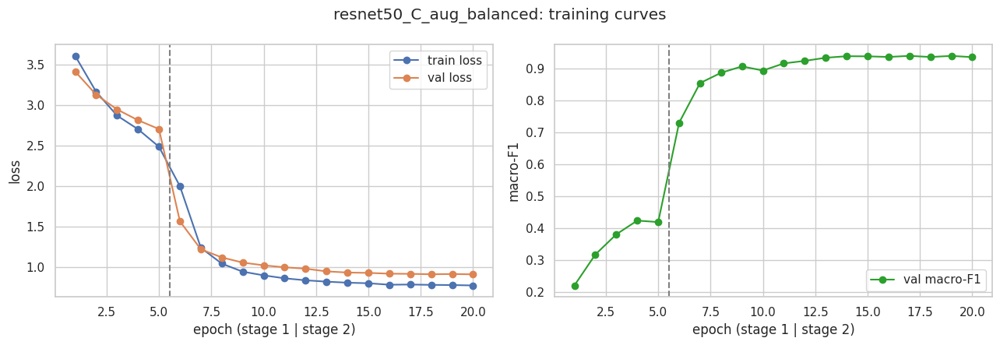

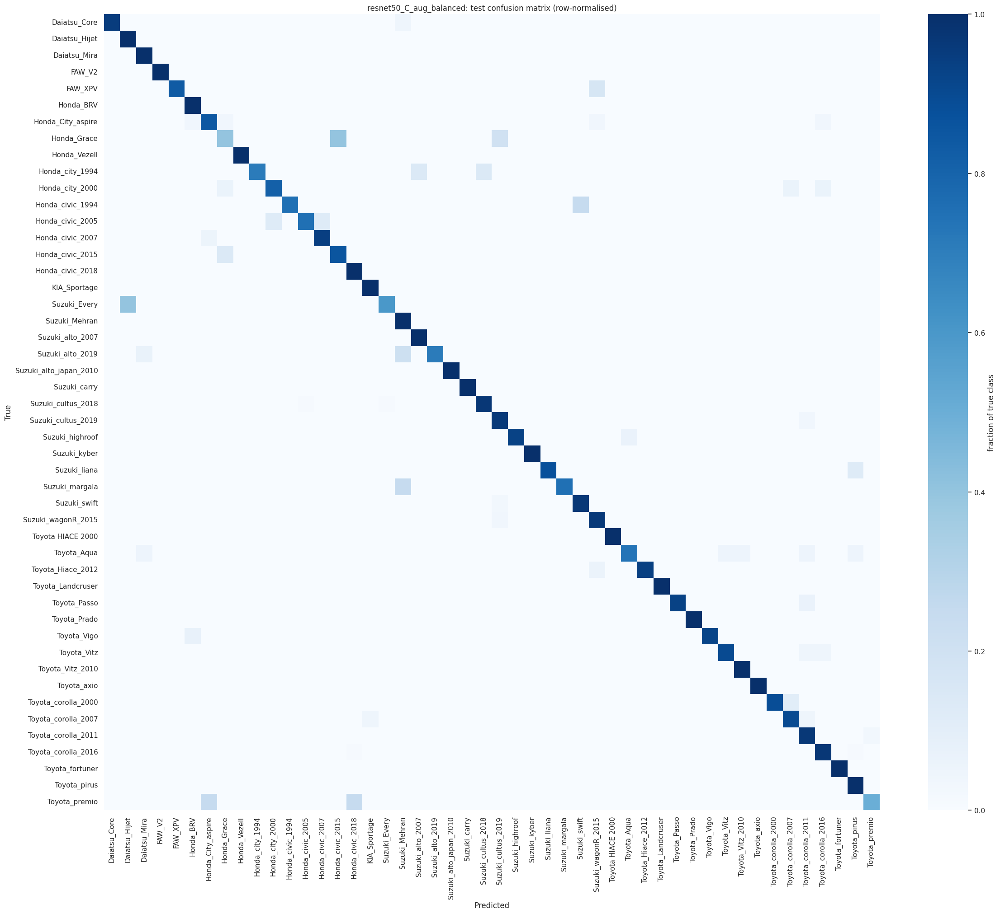


MaxViT-Tiny  |  A_no_aug_imbalanced  |  balance=False  augmentation=none
  stage 1: head only (288,304 trainable params)
  [stage 1] epoch 01 | lr 5.0e-04 | train 3.2982 | val 2.9278 | val acc 0.2624 | val macro-F1 0.0657  *best*
  [stage 1] epoch 02 | lr 5.0e-04 | train 2.8015 | val 2.6646 | val acc 0.3398 | val macro-F1 0.1641  *best*
  [stage 1] epoch 03 | lr 5.0e-04 | train 2.5678 | val 2.5200 | val acc 0.3892 | val macro-F1 0.1894  *best*
  [stage 1] epoch 04 | lr 5.0e-04 | train 2.3912 | val 2.3648 | val acc 0.4495 | val macro-F1 0.2440  *best*
  [stage 1] epoch 05 | lr 5.0e-04 | train 2.2319 | val 2.2435 | val acc 0.5097 | val macro-F1 0.2887  *best*
  stage 2: fine-tuning stages 3-4 (blocks.2, blocks.3) + new classifier (28,984,448 trainable params)
  [stage 2] epoch 06 | lr 5.0e-05 | train 1.9556 | val 1.5632 | val acc 0.7484 | val macro-F1 0.5669  *best*
  [stage 2] epoch 07 | lr 4.9e-05 | train 1.4121 | val 1.2951 | val acc 0.8624 | val macro-F1 0.7757  *best*
  [stage 2] e

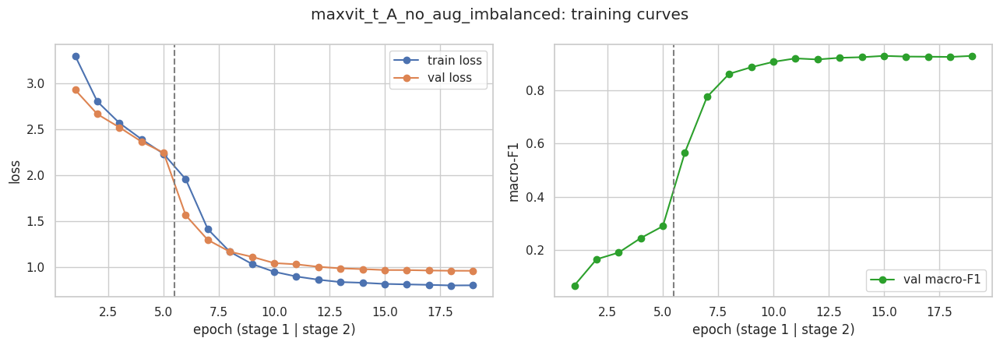

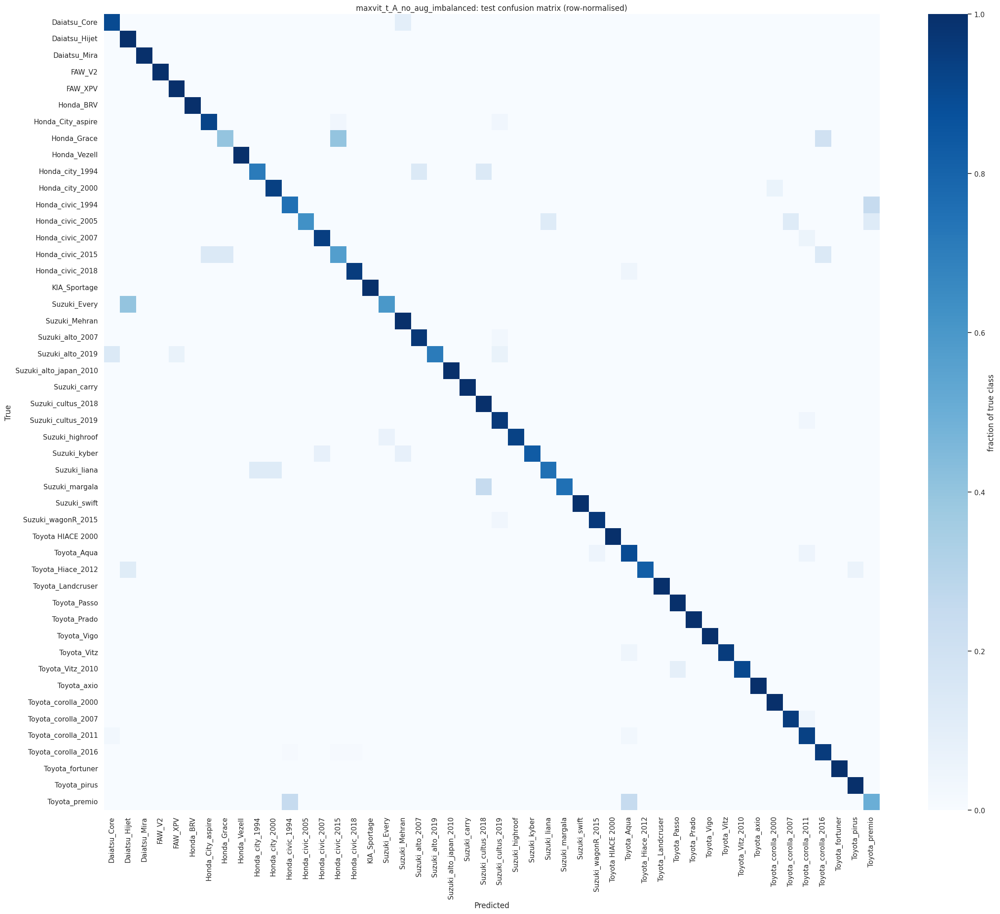


MaxViT-Tiny  |  B_no_aug_balanced  |  balance=True  augmentation=none
  stage 1: head only (288,304 trainable params)
  [stage 1] epoch 01 | lr 5.0e-04 | train 3.4574 | val 3.1651 | val acc 0.2710 | val macro-F1 0.1895  *best*
  [stage 1] epoch 02 | lr 5.0e-04 | train 2.9017 | val 2.8595 | val acc 0.3290 | val macro-F1 0.2141  *best*
  [stage 1] epoch 03 | lr 5.0e-04 | train 2.6674 | val 2.7397 | val acc 0.2968 | val macro-F1 0.2609  *best*
  [stage 1] epoch 04 | lr 5.0e-04 | train 2.4867 | val 2.6165 | val acc 0.3849 | val macro-F1 0.3569  *best*
  [stage 1] epoch 05 | lr 5.0e-04 | train 2.2409 | val 2.4950 | val acc 0.4430 | val macro-F1 0.3797  *best*
  stage 2: fine-tuning stages 3-4 (blocks.2, blocks.3) + new classifier (28,984,448 trainable params)
  [stage 2] epoch 06 | lr 5.0e-05 | train 1.9648 | val 1.6732 | val acc 0.7505 | val macro-F1 0.7074  *best*
  [stage 2] epoch 07 | lr 4.9e-05 | train 1.3680 | val 1.3532 | val acc 0.8581 | val macro-F1 0.8214  *best*
  [stage 2] epoc

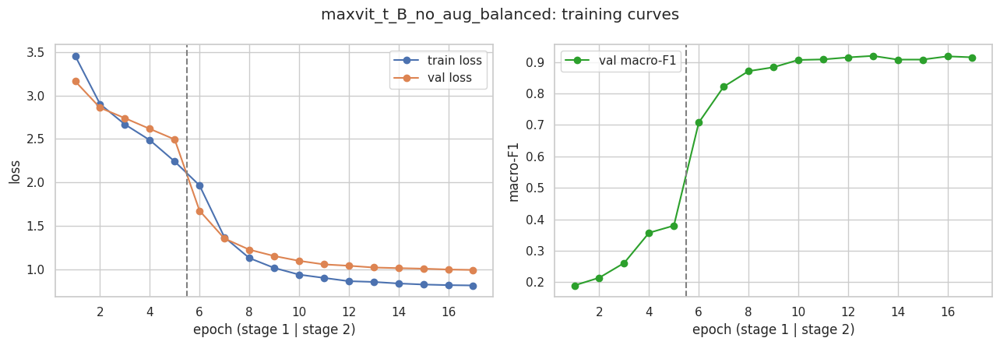

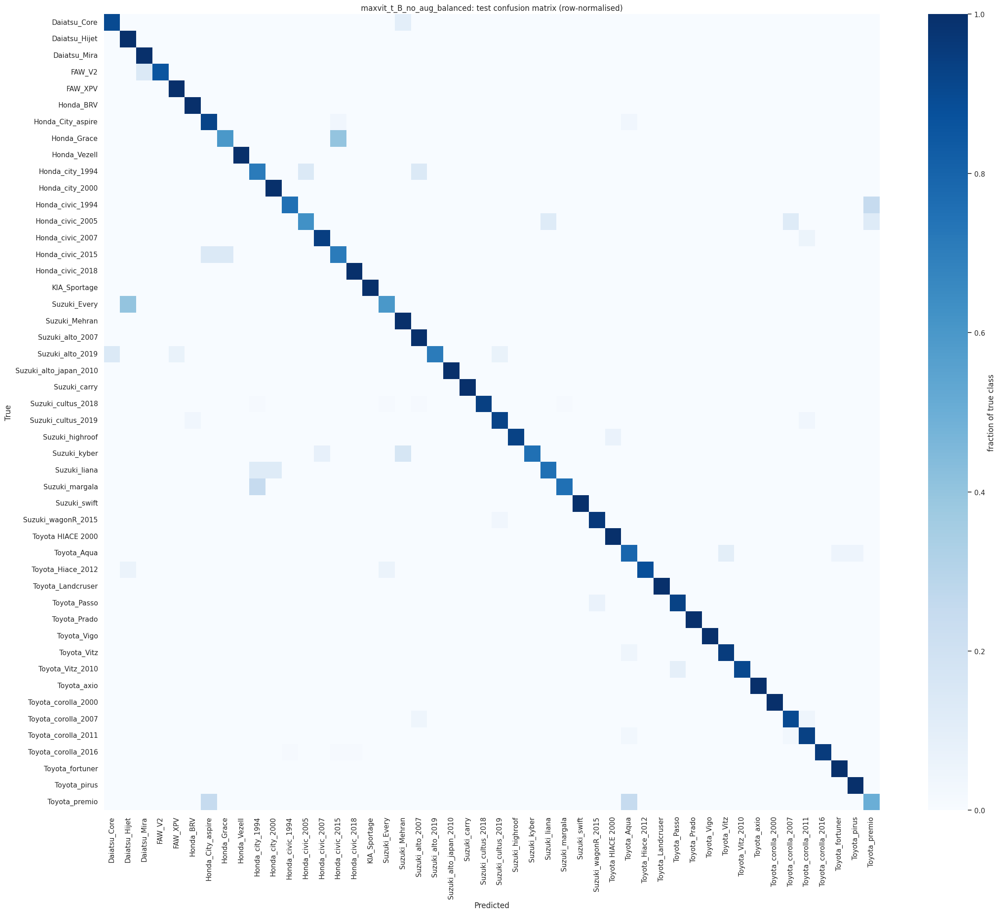


MaxViT-Tiny  |  C_aug_balanced  |  balance=True  augmentation=albumentations
  augmentation levels per class: {'standard': 24, 'strong': 24}
  stage 1: head only (288,304 trainable params)
  [stage 1] epoch 01 | lr 5.0e-04 | train 3.5042 | val 3.1533 | val acc 0.2581 | val macro-F1 0.1803  *best*
  [stage 1] epoch 02 | lr 5.0e-04 | train 3.0084 | val 2.8325 | val acc 0.3462 | val macro-F1 0.2194  *best*
  [stage 1] epoch 03 | lr 5.0e-04 | train 2.7975 | val 2.6978 | val acc 0.3183 | val macro-F1 0.2892  *best*
  [stage 1] epoch 04 | lr 5.0e-04 | train 2.6420 | val 2.6099 | val acc 0.3806 | val macro-F1 0.3535  *best*
  [stage 1] epoch 05 | lr 5.0e-04 | train 2.4328 | val 2.4893 | val acc 0.4710 | val macro-F1 0.3907  *best*
  stage 2: fine-tuning stages 3-4 (blocks.2, blocks.3) + new classifier (28,984,448 trainable params)
  [stage 2] epoch 06 | lr 5.0e-05 | train 2.1715 | val 1.7609 | val acc 0.7097 | val macro-F1 0.6389  *best*
  [stage 2] epoch 07 | lr 4.9e-05 | train 1.5851 | val

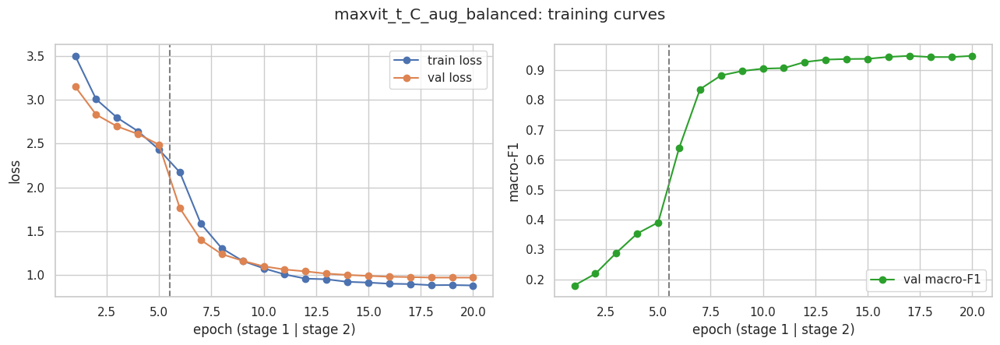

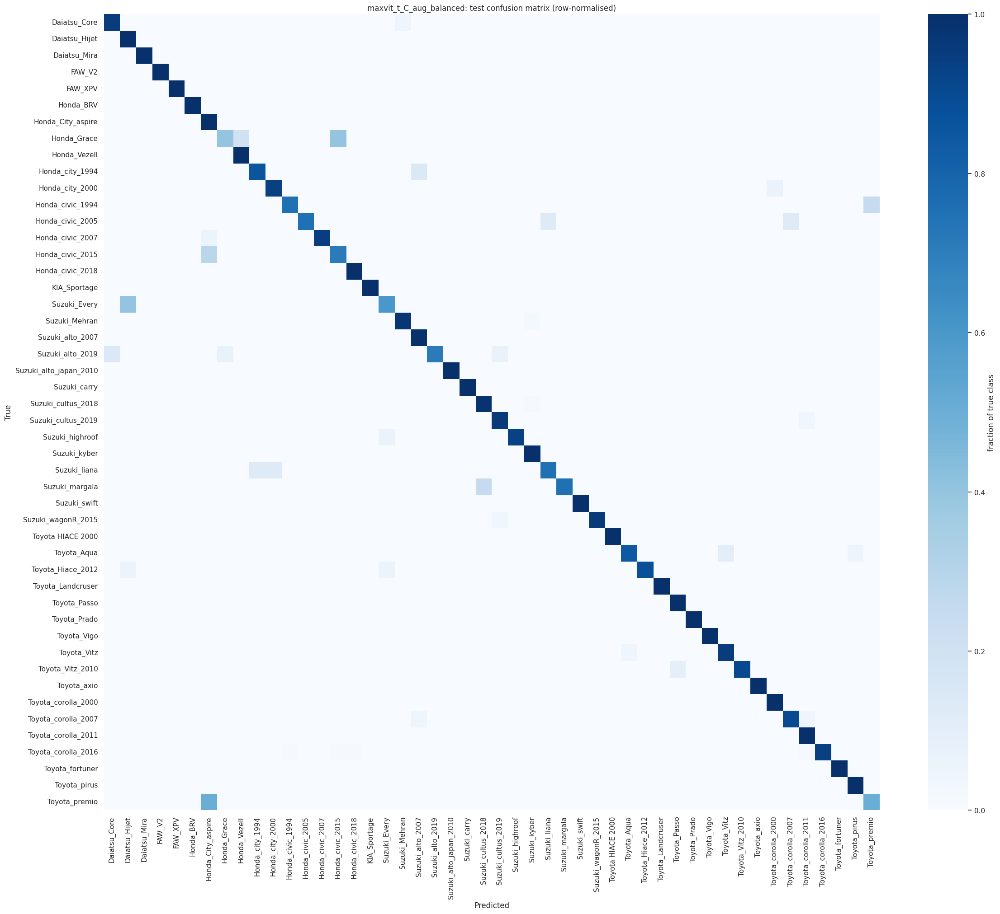

In [7]:
# =====================================================================
# 7. EXPERIMENT RUNNER
# =====================================================================
EXPERIMENTS = {
    "A_no_aug_imbalanced": {"balance": False, "augmentation": "none"},
    "B_no_aug_balanced":   {"balance": True,  "augmentation": "none"},            # BEFORE
    "C_aug_balanced":      {"balance": True,  "augmentation": "albumentations"},  # AFTER
}
BEFORE, AFTER = "B_no_aug_balanced", "C_aug_balanced"


def make_loader(ds, shuffle=False, sampler=None):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                      worker_init_fn=worker_init_fn, generator=make_generator(),
                      persistent_workers=NUM_WORKERS > 0)


def build_loaders(config):
    train_policy = make_class_policy(config["augmentation"])
    eval_policy = make_class_policy("none")
    train_ds = VehicleDataset(DATA["paths"], DATA["labels"], DATA["train_idx"], train_policy)
    val_ds = VehicleDataset(DATA["paths"], DATA["labels"], DATA["val_idx"], eval_policy)
    test_ds = VehicleDataset(DATA["test_paths"], DATA["test_labels"], np.arange(len(DATA["test_paths"])), eval_policy)
    sampler = make_balanced_sampler() if config["balance"] else None
    return {"train": make_loader(train_ds, shuffle=sampler is None, sampler=sampler),
            "val": make_loader(val_ds), "test": make_loader(test_ds)}, train_policy


def save_figure(fig, name):
    fig.tight_layout(); fig.savefig(WORK / name, dpi=150, bbox_inches="tight"); plt.show()


def plot_curves(name, history):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(h.epoch, h.train_loss, "o-", label="train loss"); axes[0].plot(h.epoch, h.val_loss, "o-", label="val loss")
    axes[0].set_ylabel("loss")
    axes[1].plot(h.epoch, h.val_macro_f1, "o-", color="tab:green", label="val macro-F1"); axes[1].set_ylabel("macro-F1")
    for ax in axes:
        ax.axvline(STAGE1_EPOCHS + 0.5, ls="--", c="gray"); ax.set_xlabel("epoch (stage 1 | stage 2)"); ax.legend()
    fig.suptitle(f"{name}: training curves")
    save_figure(fig, f"{name}_curves.png")


def plot_confusion(name, matrix):
    rows = matrix.sum(1, keepdims=True)
    norm = np.divide(matrix, rows, out=np.zeros(matrix.shape, float), where=rows > 0)
    side = max(8, 0.5 * N_CLASSES)
    fig, ax = plt.subplots(figsize=(side, side * 0.85))
    sns.heatmap(norm, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap="Blues", vmin=0, vmax=1,
                annot=N_CLASSES <= 15, fmt=".2f", ax=ax, cbar_kws={"label": "fraction of true class"})
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{name}: test confusion matrix (row-normalised)")
    plt.setp(ax.get_xticklabels(), rotation=90)
    save_figure(fig, f"{name}_confusion_matrix.png")


def try_resume(name):
    files = {k: WORK / f"{name}_{k}" for k in ("test_metrics.json", "per_class.csv", "history.csv", "preds.npz")}
    if not RESUME or not all(p.exists() for p in files.values()) or not (WORK / f"best_{name}.pt").exists():
        return None
    meta = json.loads(files["test_metrics.json"].read_text())
    preds = np.load(files["preds.npz"])
    yt, yp = preds["y_true"], preds["y_pred"]
    if len(yt) != len(DATA["test_paths"]):
        return None
    print(f"  {name}: found saved results -> loaded (set RESUME = False to retrain)")
    return dict(metrics={k: v for k, v in meta.items() if k.startswith("test_")}, y_true=yt, y_pred=yp,
                matrix=confusion_matrix(yt, yp, labels=np.arange(N_CLASSES)),
                per_class=pd.read_csv(files["per_class.csv"]),
                history=pd.read_csv(files["history.csv"]).to_dict("records"), best_val_f1=meta["best_val_macro_f1"])


def run_experiment(arch, exp_name, config):
    name = f"{arch}_{exp_name}"
    title, hp = ARCH_INFO[arch]["title"], HP[arch]
    print(f"\n{'=' * 78}\n{title}  |  {exp_name}  |  balance={config['balance']}  augmentation={config['augmentation']}\n{'=' * 78}")
    saved = try_resume(name)
    if saved is not None:
        return saved

    seed_everything(SEED)
    loaders, policy = build_loaders(config)
    if config["augmentation"] != "none":
        print("  augmentation levels per class:", pd.Series(policy).value_counts().to_dict())

    model = build_model(arch, N_CLASSES).to(DEVICE)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    state = dict(step=0, best_f1=-1.0, history=[], checkpoint=WORK / f"best_{name}.pt")

    # ---- stage 1: head only ----
    mods1 = stage_modules(arch, model, 1); set_trainable(model, mods1)
    n1 = sum(p.numel() for p in model.parameters() if p.requires_grad)
    opt1 = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=hp["lr_stage1"], weight_decay=hp["weight_decay"])
    print(f"  stage 1: head only ({n1:,} trainable params)")
    t0 = time.time()
    fit_stage(model, 1, STAGE1_EPOCHS, opt1, None, mods1, loaders, criterion, state)

    # ---- stage 2: head + upper backbone ----
    mods2 = stage_modules(arch, model, 2); set_trainable(model, mods2)
    n2 = sum(p.numel() for p in model.parameters() if p.requires_grad)
    backbone_params = [p for m in mods2[1:] for p in m.parameters()]
    head_params = list(mods2[0].parameters())
    opt2 = torch.optim.AdamW([{"params": backbone_params, "lr": hp["lr_backbone"]},
                              {"params": head_params, "lr": hp["lr_head"]}], weight_decay=hp["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=STAGE2_EPOCHS)
    print(f"  stage 2: fine-tuning {ARCH_INFO[arch]['stage2_text']} ({n2:,} trainable params)")
    fit_stage(model, 2, STAGE2_EPOCHS, opt2, sched, mods2, loaders, criterion, state, PATIENCE)
    minutes = (time.time() - t0) / 60

    # ---- evaluate best checkpoint on the untouched test set ----
    model.load_state_dict(torch.load(state["checkpoint"], map_location=DEVICE))
    frozen_same, moved = verify_transfer(arch, model)
    print(f"  transfer check: frozen layers identical to ImageNet = {frozen_same} | fine-tuned tensors changed = {moved:.0%}")
    assert frozen_same, "frozen backbone changed: transfer learning is broken"
    _, y_pred, y_true = predict(model, loaders["test"], criterion)
    metrics = compute_metrics(y_true, y_pred, "test")
    print(f"  >>> TEST  acc {metrics['test_acc']:.4f} | balanced acc {metrics['test_balanced_acc']:.4f} | "
          f"macro-F1 {metrics['test_macro_f1']:.4f}   ({minutes:.1f} min)")

    labels = np.arange(N_CLASSES)
    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    plot_curves(name, state["history"]); plot_confusion(name, matrix)
    prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    per_class = pd.DataFrame(dict(class_name=CLASS_NAMES, train_count=TRAIN_COUNTS, test_support=sup,
                                  precision=prec, recall=rec, f1=f1))
    per_class.to_csv(WORK / f"{name}_per_class.csv", index=False)
    pd.DataFrame(state["history"]).to_csv(WORK / f"{name}_history.csv", index=False)
    np.savez(WORK / f"{name}_preds.npz", y_true=y_true, y_pred=y_pred)
    (WORK / f"{name}_classification_report.txt").write_text(classification_report(
        y_true, y_pred, labels=labels, target_names=CLASS_NAMES, zero_division=0, digits=4))
    (WORK / f"{name}_test_metrics.json").write_text(json.dumps(
        {**metrics, "best_val_macro_f1": state["best_f1"], "config": config, "model": arch,
         "pretrained_source": PRETRAINED[arch][1], "frozen_layers_identical": frozen_same}, indent=2))

    del model; torch.cuda.empty_cache()
    return dict(metrics=metrics, y_true=y_true, y_pred=y_pred, matrix=matrix, per_class=per_class,
                history=state["history"], best_val_f1=state["best_f1"])


RESULTS = {arch: {} for arch in ARCHS}
for arch in ARCHS:
    for exp_name, exp_cfg in EXPERIMENTS.items():
        RESULTS[arch][exp_name] = run_experiment(arch, exp_name, exp_cfg)

---
## 8. Results comparison
All numbers are on the **untouched test set**, using each run's best-validation-macro-F1 checkpoint.
Balanced accuracy, macro-F1 and macro-recall weight every class equally, so they show whether small classes are being sacrificed.
`test_errors` is the raw count of misclassified test images.

,model,experiment,balance,augmentation,test_images,test_errors,test_acc,test_balanced_acc,test_macro_f1,test_weighted_f1,test_macro_precision,test_macro_recall,best_val_macro_f1
0,ResNet50,A_no_aug_imbalanced,False,none,751,74,0.9015,0.8237,0.8435,0.8951,0.8909,0.8237,0.8890
1,ResNet50,B_no_aug_balanced,True,none,751,95,0.8735,0.7809,0.8105,0.8667,0.8891,0.7809,0.8722
2,ResNet50,C_aug_balanced,True,albumentations,751,51,0.9321,0.9011,0.9063,0.9312,0.9214,0.9011,0.9404
3,MaxViT-Tiny,A_no_aug_imbalanced,False,none,751,49,0.9348,0.8981,0.9021,0.9339,0.9149,0.8981,0.9301
4,MaxViT-Tiny,B_no_aug_balanced,True,none,751,54,0.9281,0.8981,0.8945,0.9279,0.8970,0.8981,0.9196
5,MaxViT-Tiny,C_aug_balanced,True,albumentations,751,41,0.9454,0.9139,0.9158,0.9445,0.9248,0.9139,0.9465


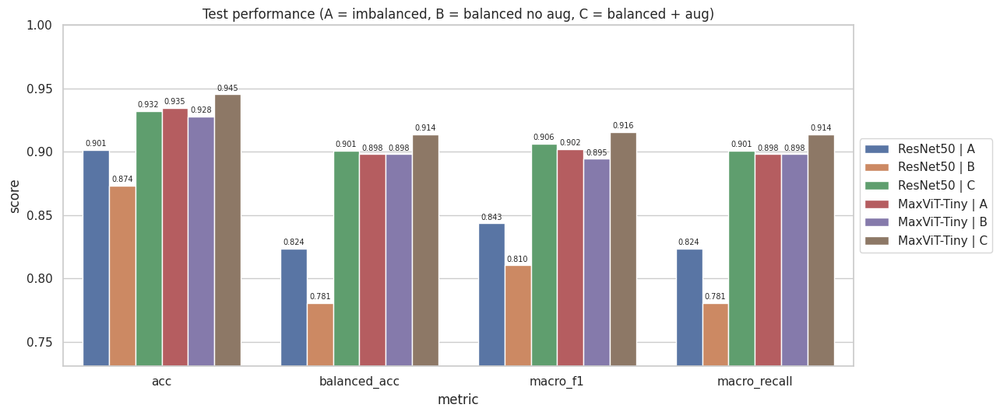

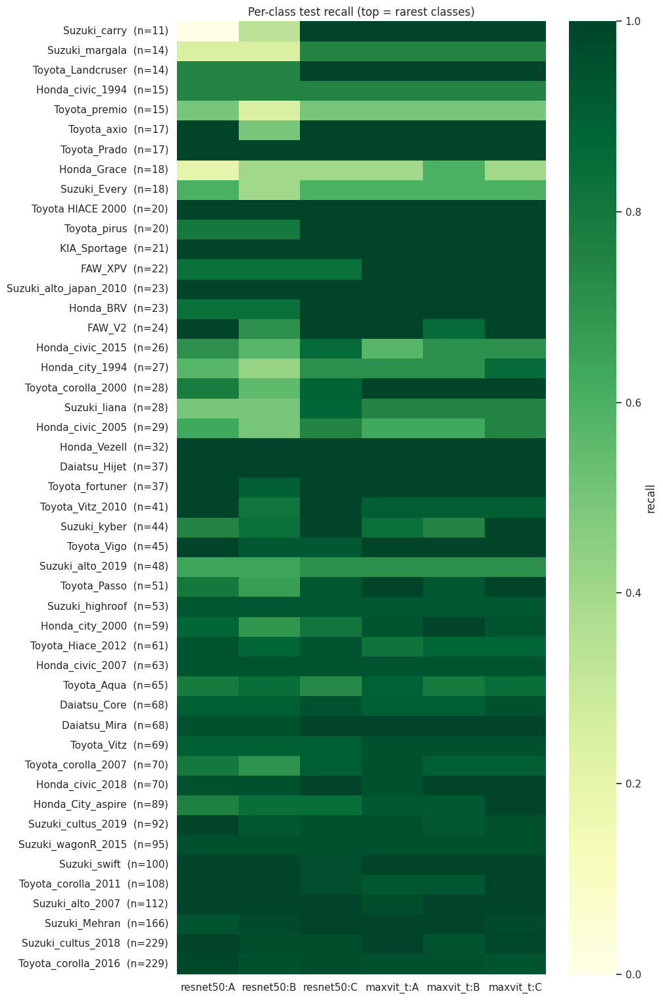

In [8]:
# =====================================================================
# 8. RESULTS COMPARISON (both models)
# =====================================================================
rows = []
for arch in ARCHS:
    for exp, r in RESULTS[arch].items():
        yt, yp = r["y_true"], r["y_pred"]
        rows.append({"model": ARCH_INFO[arch]["title"], "experiment": exp, **EXPERIMENTS[exp],
                     "test_images": len(yt), "test_errors": int((yt != yp).sum()),
                     **r["metrics"], "best_val_macro_f1": r["best_val_f1"]})
comparison = pd.DataFrame(rows)
comparison.to_csv(WORK / "04_experiment_comparison.csv", index=False)
display(comparison.round(4))

# ---- grouped bar chart ----
metric_cols = ["test_acc", "test_balanced_acc", "test_macro_f1", "test_macro_recall"]
comparison["run"] = comparison["model"] + " | " + comparison["experiment"].str[0]
long = comparison.melt(id_vars="run", value_vars=metric_cols, var_name="metric", value_name="score")
long["metric"] = long["metric"].str.replace("test_", "", regex=False)
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.barplot(data=long, x="metric", y="score", hue="run", ax=ax)
ax.set_ylim(max(0.0, long["score"].min() - 0.05), 1.0)
ax.set_title("Test performance (A = imbalanced, B = balanced no aug, C = balanced + aug)")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=7, padding=2)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout(); fig.savefig(WORK / "04_metric_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- per-class recall heatmap (rarest classes on top) ----
recall_df = pd.DataFrame({f"{arch}:{exp[0]}": r["per_class"].set_index("class_name")["recall"]
                          for arch in ARCHS for exp, r in RESULTS[arch].items()})
order = pd.Series(TRAIN_COUNTS, index=CLASS_NAMES).sort_values().index
recall_df = recall_df.loc[order]
ylabels = [f"{c}  (n={TRAIN_COUNTS[CLASS_NAMES.index(c)]})" for c in recall_df.index]
fig, ax = plt.subplots(figsize=(10, max(4, 0.32 * N_CLASSES)))
sns.heatmap(recall_df.values, annot=N_CLASSES <= 30, fmt=".2f", cmap="YlGn", vmin=0, vmax=1,
            xticklabels=recall_df.columns, yticklabels=ylabels, ax=ax, cbar_kws={"label": "recall"})
ax.set_title("Per-class test recall (top = rarest classes)")
fig.tight_layout(); fig.savefig(WORK / "05_per_class_recall_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

---
## 9. Misclassification analysis: before vs after augmentation (per model)
B and C see the same test images in the same order, so each image can be compared directly:

| Group | Meaning |
|-------|---------|
| **Fixed** | wrong in B, correct in C |
| **Broken** | correct in B, wrong in C |
| **Still wrong / correct** | same result in both |

An exact **McNemar test** (binomial test on fixed vs broken) says whether the net change is more than chance.


##############################################################################
#  ResNet50
##############################################################################


,group,images,share_of_test_set
0,Errors BEFORE (B),95,0.1265
1,Errors AFTER (C),51,0.0679
2,Fixed,55,0.0732
3,Newly broken,11,0.0146
4,Still wrong,40,0.0533
5,Still correct,645,0.8589
6,Net errors removed,44,0.0586


Error rate  BEFORE: 0.1265   AFTER: 0.0679
McNemar exact test (fixed=55, broken=11)  p = 0.0000  -> significant (p < 0.05)


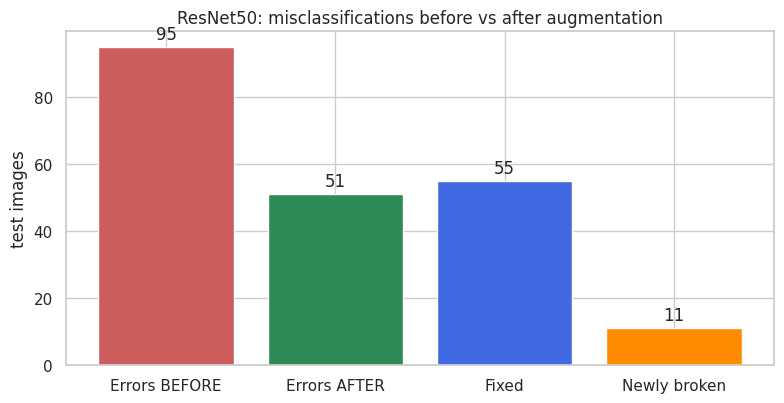

,class_name,train_count,group,test_support,errors_before,errors_after,recall_before,recall_after,recall_change
0,Suzuki_carry,11,minority,3,2,0,0.3333,1.0000,0.6667
1,Suzuki_margala,14,minority,4,3,1,0.2500,0.7500,0.5000
2,Toyota_axio,17,minority,4,2,0,0.5000,1.0000,0.5000
3,Suzuki_liana,28,minority,8,4,1,0.5000,0.8750,0.3750
4,Toyota_corolla_2000,28,minority,9,4,1,0.5556,0.8889,0.3333
5,Honda_city_1994,27,minority,7,4,2,0.4286,0.7143,0.2857
6,Honda_civic_2015,26,minority,7,3,1,0.5714,0.8571,0.2857
7,FAW_V2,24,minority,7,2,0,0.7143,1.0000,0.2857
8,Toyota_Passo,51,majority,15,5,1,0.6667,0.9333,0.2667
9,Toyota_Landcruser,14,minority,4,1,0,0.7500,1.0000,0.2500



Minority classes (fewer training images than the median class) vs majority:


,classes,test_images,errors_before,errors_after,error_rate_before,error_rate_after
group,,,,,,
majority,24,604,52,34,0.0861,0.0563
minority,24,147,43,17,0.2925,0.1156


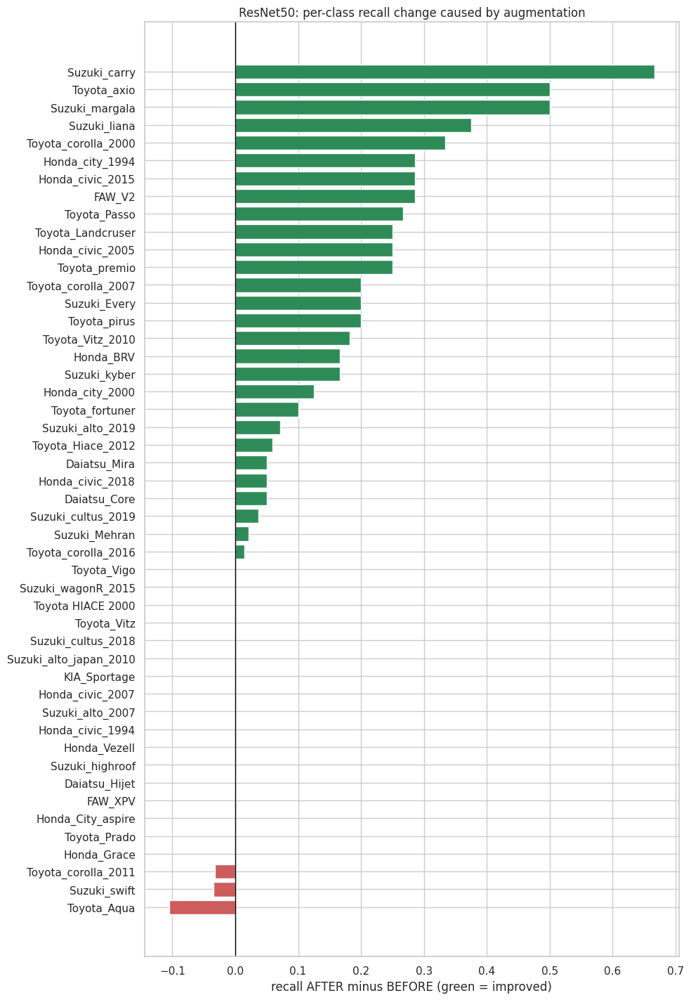


Most frequent confusions (negative change = fewer mistakes after augmentation):


,true_class,predicted_as,mistakes_before,mistakes_after,change
0,Suzuki_alto_2019,Suzuki_Mehran,1,3,2
1,Honda_city_1994,Suzuki_cultus_2018,3,1,-2
2,Suzuki_Every,Daiatsu_Hijet,2,2,0
3,Honda_City_aspire,Toyota_corolla_2016,3,1,-2
4,Suzuki_liana,Honda_city_2000,3,0,-3
5,Toyota_Vitz,Toyota_corolla_2016,2,1,-1
6,Honda_Grace,Honda_civic_2015,1,2,1
7,Toyota_corolla_2007,Honda_city_2000,2,0,-2
8,Suzuki_margala,Suzuki_cultus_2018,2,0,-2
9,Honda_civic_2015,Honda_Grace,1,1,0


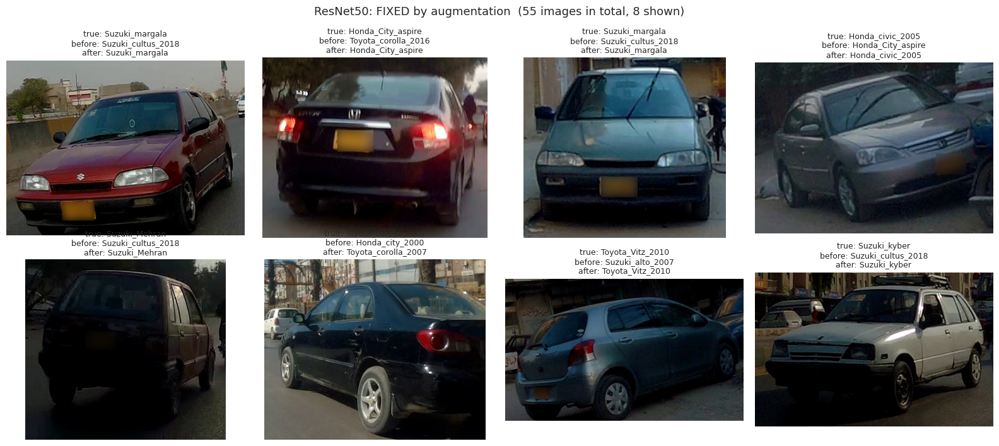

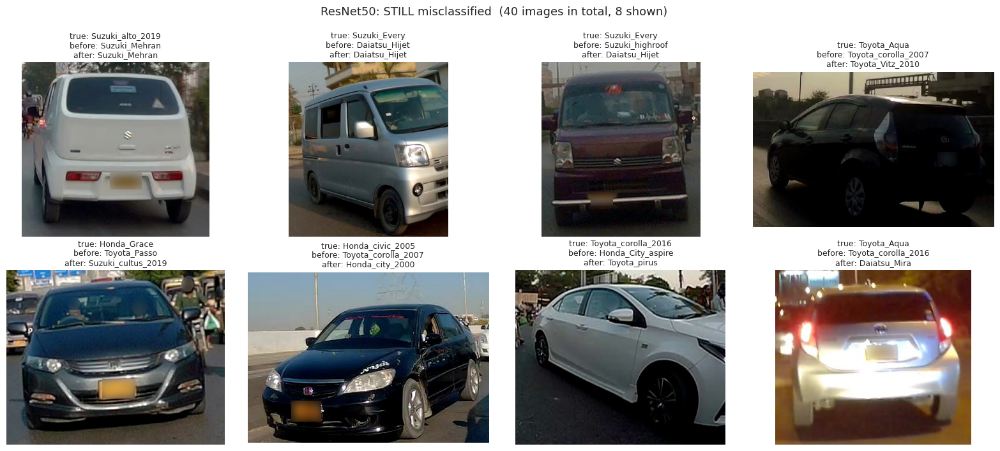

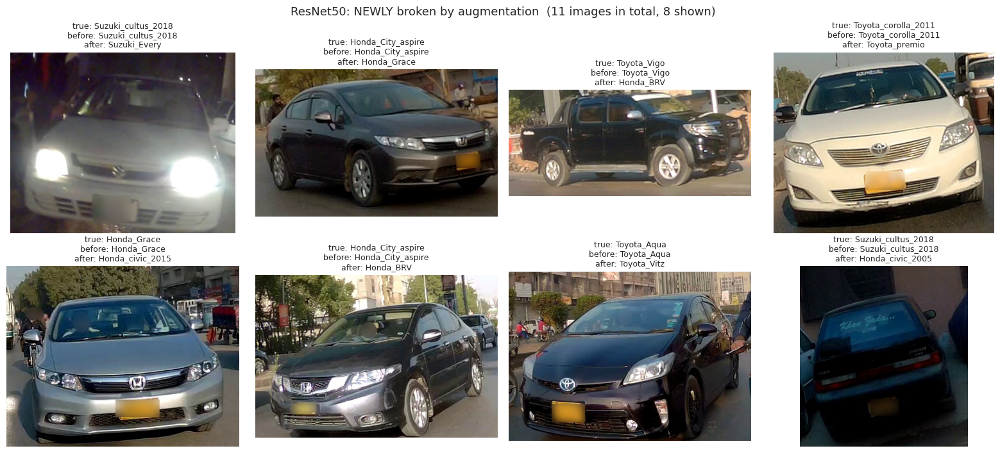


##############################################################################
#  MaxViT-Tiny
##############################################################################


,group,images,share_of_test_set
0,Errors BEFORE (B),54,0.0719
1,Errors AFTER (C),41,0.0546
2,Fixed,17,0.0226
3,Newly broken,4,0.0053
4,Still wrong,37,0.0493
5,Still correct,693,0.9228
6,Net errors removed,13,0.0173


Error rate  BEFORE: 0.0719   AFTER: 0.0546
McNemar exact test (fixed=17, broken=4)  p = 0.0072  -> significant (p < 0.05)


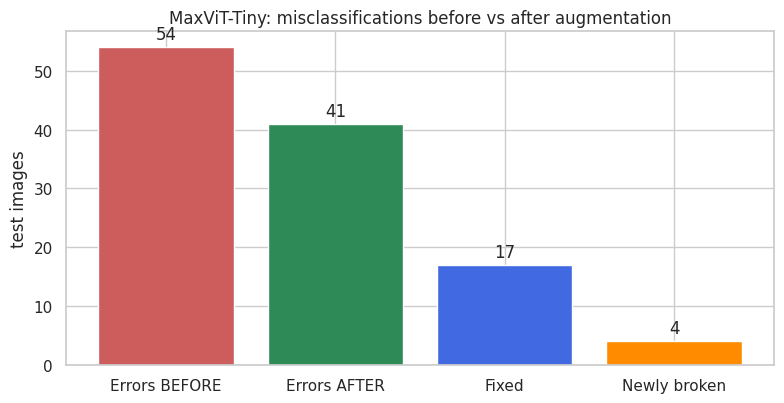

,class_name,train_count,group,test_support,errors_before,errors_after,recall_before,recall_after,recall_change
0,Suzuki_kyber,44,majority,12,3,0,0.7500,1.0000,0.2500
1,FAW_V2,24,minority,7,1,0,0.8571,1.0000,0.1429
2,Honda_city_1994,27,minority,7,2,1,0.7143,0.8571,0.1429
3,Honda_civic_2005,29,minority,8,3,2,0.6250,0.7500,0.1250
4,Honda_City_aspire,89,majority,26,2,0,0.9231,1.0000,0.0769
5,Toyota_Passo,51,majority,15,1,0,0.9333,1.0000,0.0667
6,Toyota_corolla_2011,108,majority,31,2,0,0.9355,1.0000,0.0645
7,Toyota_Aqua,65,majority,19,4,3,0.7895,0.8421,0.0526
8,Daiatsu_Core,68,majority,20,2,1,0.9000,0.9500,0.0500
9,Suzuki_cultus_2018,229,majority,67,4,1,0.9403,0.9851,0.0448



Minority classes (fewer training images than the median class) vs majority:


,classes,test_images,errors_before,errors_after,error_rate_before,error_rate_after
group,,,,,,
majority,24,604,36,25,0.0596,0.0414
minority,24,147,18,16,0.1224,0.1088


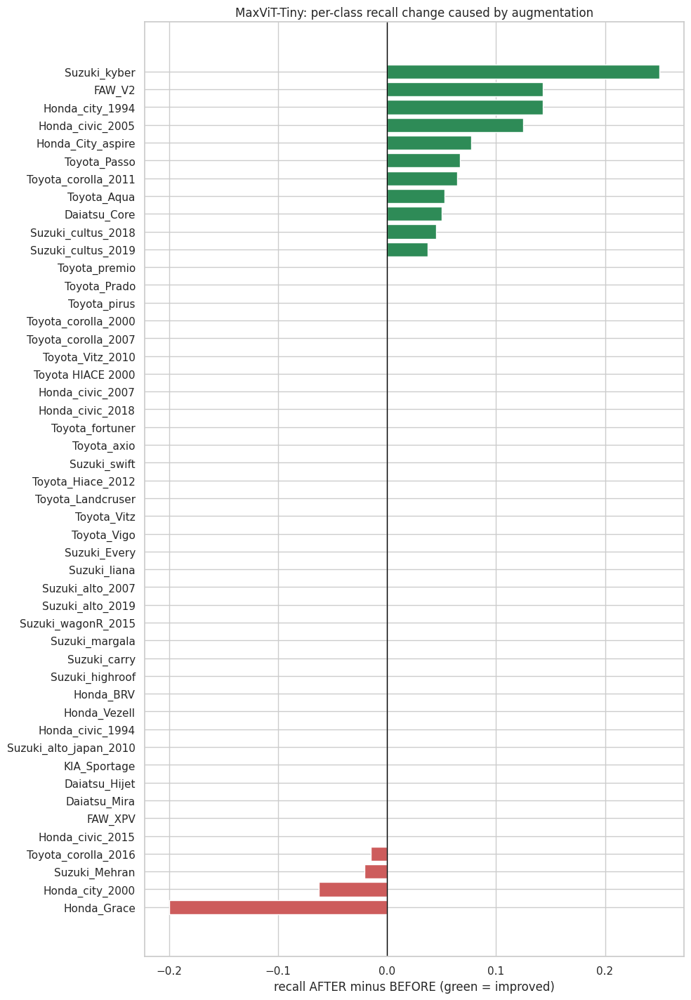


Most frequent confusions (negative change = fewer mistakes after augmentation):


,true_class,predicted_as,mistakes_before,mistakes_after,change
0,Suzuki_alto_2019,Daiatsu_Core,2,2,0
1,Toyota_Aqua,Toyota_Vitz,2,2,0
2,Suzuki_Every,Daiatsu_Hijet,2,2,0
3,Honda_Grace,Honda_civic_2015,2,2,0
4,Honda_civic_2015,Honda_City_aspire,1,2,1
5,Toyota_premio,Honda_City_aspire,1,2,1
6,Daiatsu_Core,Suzuki_Mehran,2,1,-1
7,Toyota_Hiace_2012,Daiatsu_Hijet,1,1,0
8,Honda_city_1994,Suzuki_alto_2007,1,1,0
9,Toyota_Aqua,Toyota_pirus,1,1,0


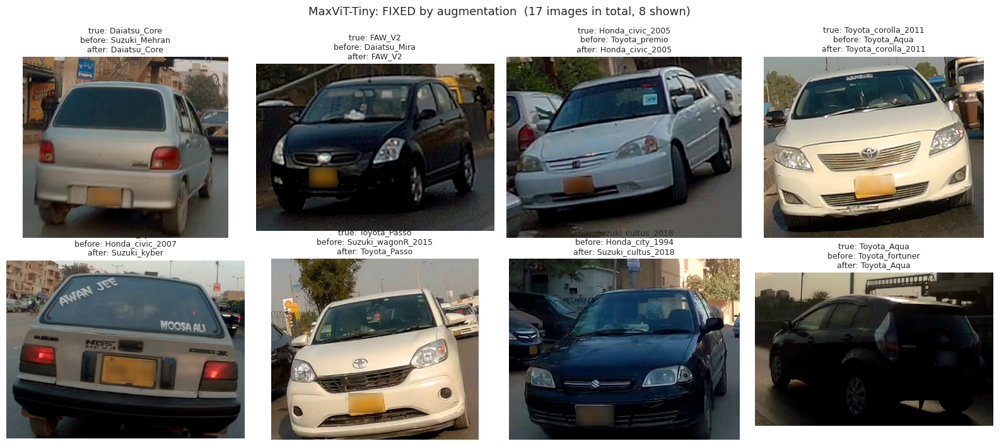

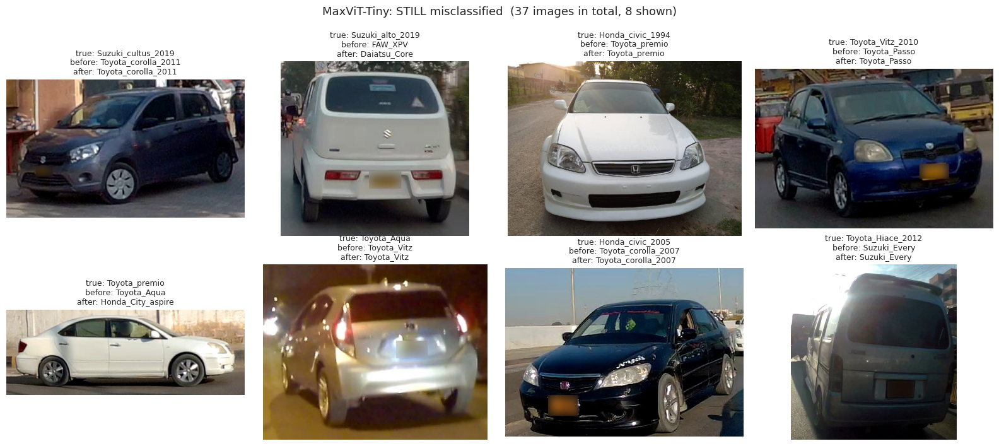

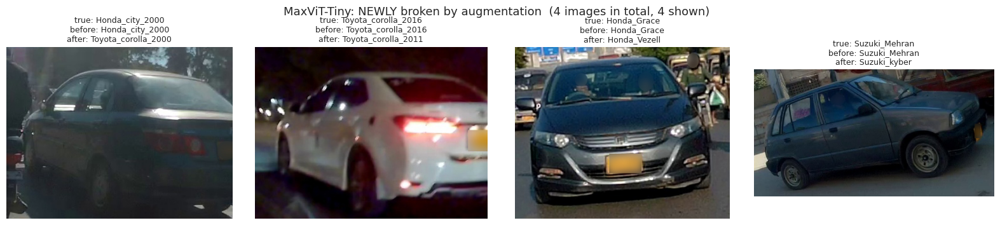

In [9]:
# =====================================================================
# 9. BEFORE / AFTER ANALYSIS (runs for each model)
# =====================================================================
ANALYSIS = {}

def show_gallery(mask, title, filename, yt, pb, pa, max_images=8, seed=SEED):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        print(f"{title}: none"); return
    idx = np.random.RandomState(seed).choice(idx, size=min(max_images, len(idx)), replace=False)
    cols = min(4, len(idx)); rows_n = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 3.6 * rows_n), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(Image.open(DATA["test_paths"][i]).convert("RGB"))
        ax.set_title(f"true: {CLASS_NAMES[yt[i]]}\nbefore: {CLASS_NAMES[pb[i]]}\nafter: {CLASS_NAMES[pa[i]]}", fontsize=9)
    fig.suptitle(f"{title}  ({int(mask.sum())} images in total, {len(idx)} shown)", fontsize=13)
    fig.tight_layout(); fig.savefig(WORK / filename, dpi=130, bbox_inches="tight"); plt.show()


def analyze_before_after(arch):
    title = ARCH_INFO[arch]["title"]
    rb, ra = RESULTS[arch][BEFORE], RESULTS[arch][AFTER]
    yt, pb, pa = rb["y_true"], rb["y_pred"], ra["y_pred"]
    assert np.array_equal(yt, ra["y_true"]) and len(yt) == len(DATA["test_paths"]), "test order mismatch"

    wrong_b, wrong_a = pb != yt, pa != yt
    fixed, broken = wrong_b & ~wrong_a, ~wrong_b & wrong_a
    still_wrong, still_ok = wrong_b & wrong_a, ~wrong_b & ~wrong_a
    n_fixed, n_broken = int(fixed.sum()), int(broken.sum())
    p_value = binomtest(n_fixed, n_fixed + n_broken, 0.5).pvalue if (n_fixed + n_broken) > 0 else 1.0

    summary = pd.DataFrame({
        "group": ["Errors BEFORE (B)", "Errors AFTER (C)", "Fixed", "Newly broken", "Still wrong", "Still correct", "Net errors removed"],
        "images": [int(wrong_b.sum()), int(wrong_a.sum()), n_fixed, n_broken, int(still_wrong.sum()),
                   int(still_ok.sum()), int(wrong_b.sum() - wrong_a.sum())]})
    summary["share_of_test_set"] = (summary["images"] / len(yt)).round(4)
    display(summary)
    print(f"Error rate  BEFORE: {wrong_b.mean():.4f}   AFTER: {wrong_a.mean():.4f}")
    print(f"McNemar exact test (fixed={n_fixed}, broken={n_broken})  p = {p_value:.4f}  -> "
          f"{'significant (p < 0.05)' if p_value < 0.05 else 'not significant at 5 %'}")

    fig, ax = plt.subplots(figsize=(8, 4.2))
    bars = ax.bar(["Errors BEFORE", "Errors AFTER", "Fixed", "Newly broken"],
                  [wrong_b.sum(), wrong_a.sum(), n_fixed, n_broken], color=["indianred", "seagreen", "royalblue", "darkorange"])
    ax.bar_label(bars, padding=3); ax.set_ylabel("test images")
    ax.set_title(f"{title}: misclassifications before vs after augmentation")
    fig.tight_layout(); fig.savefig(WORK / f"06_{arch}_errors_before_after.png", dpi=150); plt.show()

    # ---- per class ----
    errors_b = np.bincount(yt[wrong_b], minlength=N_CLASSES)
    errors_a = np.bincount(yt[wrong_a], minlength=N_CLASSES)
    support = np.bincount(yt, minlength=N_CLASSES)
    safe = lambda e: np.divide(support - e, support, out=np.zeros(N_CLASSES), where=support > 0)
    per_class_cmp = pd.DataFrame({
        "class_name": CLASS_NAMES, "train_count": TRAIN_COUNTS,
        "group": np.where(TRAIN_COUNTS < np.median(TRAIN_COUNTS), "minority", "majority"),
        "test_support": support, "errors_before": errors_b, "errors_after": errors_a,
        "recall_before": safe(errors_b), "recall_after": safe(errors_a)})
    per_class_cmp["recall_change"] = per_class_cmp["recall_after"] - per_class_cmp["recall_before"]
    per_class_cmp = per_class_cmp.sort_values("recall_change", ascending=False).reset_index(drop=True)
    per_class_cmp.to_csv(WORK / f"07_{arch}_per_class_before_after.csv", index=False)
    display(per_class_cmp.round(4))

    grp = per_class_cmp.groupby("group").agg(classes=("class_name", "count"), test_images=("test_support", "sum"),
                                             errors_before=("errors_before", "sum"), errors_after=("errors_after", "sum"))
    grp["error_rate_before"] = grp["errors_before"] / grp["test_images"]
    grp["error_rate_after"] = grp["errors_after"] / grp["test_images"]
    print("\nMinority classes (fewer training images than the median class) vs majority:")
    display(grp.round(4))

    plot_df = per_class_cmp.sort_values("recall_change")
    fig, ax = plt.subplots(figsize=(10, max(4, 0.3 * N_CLASSES)))
    ax.barh(plot_df["class_name"], plot_df["recall_change"], color=np.where(plot_df["recall_change"] >= 0, "seagreen", "indianred"))
    ax.axvline(0, c="black", lw=1); ax.set_xlabel("recall AFTER minus BEFORE (green = improved)")
    ax.set_title(f"{title}: per-class recall change caused by augmentation")
    fig.tight_layout(); fig.savefig(WORK / f"08_{arch}_recall_change_per_class.png", dpi=150); plt.show()

    # ---- most frequent confusions ----
    mB, mA = rb["matrix"].copy(), ra["matrix"].copy()
    np.fill_diagonal(mB, 0); np.fill_diagonal(mA, 0)
    top = lambda m, k=10: {(i, j) for i, j in zip(*np.unravel_index(np.argsort(m, axis=None)[::-1][:k], m.shape)) if m[i, j] > 0}
    pairs = sorted(top(mB) | top(mA), key=lambda p: -(mB[p] + mA[p]))
    pair_df = pd.DataFrame({"true_class": [CLASS_NAMES[i] for i, _ in pairs], "predicted_as": [CLASS_NAMES[j] for _, j in pairs],
                            "mistakes_before": [int(mB[p]) for p in pairs], "mistakes_after": [int(mA[p]) for p in pairs]})
    pair_df["change"] = pair_df["mistakes_after"] - pair_df["mistakes_before"]
    pair_df.to_csv(WORK / f"09_{arch}_top_confusions.csv", index=False)
    print("\nMost frequent confusions (negative change = fewer mistakes after augmentation):")
    display(pair_df)

    # ---- visual proof ----
    show_gallery(fixed, f"{title}: FIXED by augmentation", f"11_{arch}_gallery_fixed.png", yt, pb, pa)
    show_gallery(still_wrong, f"{title}: STILL misclassified", f"12_{arch}_gallery_still_wrong.png", yt, pb, pa)
    show_gallery(broken, f"{title}: NEWLY broken by augmentation", f"13_{arch}_gallery_broken.png", yt, pb, pa)

    minority = grp.loc["minority"] if "minority" in grp.index else None
    ANALYSIS[arch] = dict(err_b=int(wrong_b.sum()), err_a=int(wrong_a.sum()), fixed=n_fixed, broken=n_broken,
                          p=p_value, minority=minority)


for arch in ARCHS:
    print("\n" + "#" * 78 + f"\n#  {ARCH_INFO[arch]['title']}\n" + "#" * 78)
    analyze_before_after(arch)

---
## 10. Verdict, model comparison and export
The next cell writes an evidence-based verdict from the numbers above (nothing is hard-coded), compares the two models
head to head, then packages the final models and all results into one zip.

In [10]:
# =====================================================================
# 10. AUTOMATIC VERDICT + MODEL HEAD-TO-HEAD
# =====================================================================
def verdict_text(a):
    if a["err_a"] < a["err_b"] and a["p"] < 0.05: return "YES: augmentation significantly reduced misclassifications."
    if a["err_a"] < a["err_b"]:                  return "PARTLY: fewer errors, but within random variation (not significant)."
    if a["err_a"] == a["err_b"]:                 return "NO CHANGE: same number of misclassifications."
    return "NO: augmentation did not help on this test set (more errors)."

lines = ["=" * 78, "FINAL VERDICT", "=" * 78,
         f"Balancing check : imbalance {TRAIN_COUNTS.max() / TRAIN_COUNTS.min():.1f}x -> "
         f"{balanced_counts.max() / max(balanced_counts.min(), 1):.2f}x per epoch with the sampler"]
for arch in ARCHS:
    mA_ = RESULTS[arch]["A_no_aug_imbalanced"]["metrics"]; mB_ = RESULTS[arch][BEFORE]["metrics"]; mC_ = RESULTS[arch][AFTER]["metrics"]
    a = ANALYSIS[arch]
    lines += ["", f"--- {ARCH_INFO[arch]['title']}  (transfer learning ON: {PRETRAINED[arch][1]})",
              f"A imbalanced, no aug : acc {mA_['test_acc']:.4f} | macro-F1 {mA_['test_macro_f1']:.4f}",
              f"B balanced, no aug   : acc {mB_['test_acc']:.4f} | macro-F1 {mB_['test_macro_f1']:.4f} | errors {a['err_b']}",
              f"C balanced + aug     : acc {mC_['test_acc']:.4f} | macro-F1 {mC_['test_macro_f1']:.4f} | errors {a['err_a']}",
              f"Misclassifications   : {a['err_b']} -> {a['err_a']} (net {a['err_b'] - a['err_a']:+d}; fixed {a['fixed']}, broken {a['broken']}; McNemar p = {a['p']:.4f})",
              f"Did augmentation help? {verdict_text(a)}"]
    if a["minority"] is not None:
        lines.append(f"Minority classes     : error rate {a['minority']['error_rate_before']:.3f} -> {a['minority']['error_rate_after']:.3f}")

# ---- final model per architecture: chosen by VALIDATION macro-F1 (never by test) ----
FINAL = {arch: max((BEFORE, AFTER), key=lambda n: RESULTS[arch][n]["best_val_f1"]) for arch in ARCHS}
lines += ["", "--- Model head-to-head (each model's final run, chosen by validation macro-F1)"]
for arch in ARCHS:
    r = RESULTS[arch][FINAL[arch]]
    lines.append(f"{ARCH_INFO[arch]['title']:12s}: run {FINAL[arch]} | test acc {r['metrics']['test_acc']:.4f} | "
                 f"macro-F1 {r['metrics']['test_macro_f1']:.4f} | errors {int((r['y_true'] != r['y_pred']).sum())}")
if len(ARCHS) == 2:
    r1, r2 = (RESULTS[a][FINAL[a]] for a in ARCHS)
    ok1, ok2 = r1["y_pred"] == r1["y_true"], r2["y_pred"] == r2["y_true"]
    only1, only2 = int((ok1 & ~ok2).sum()), int((~ok1 & ok2).sum())
    p_models = binomtest(only1, only1 + only2, 0.5).pvalue if only1 + only2 else 1.0
    lines.append(f"Only {ARCH_INFO[ARCHS[0]]['title']} correct: {only1} | only {ARCH_INFO[ARCHS[1]]['title']} correct: {only2} | McNemar p = {p_models:.4f}")
lines.append("=" * 78)
VERDICT_TEXT = "\n".join(lines)
print(VERDICT_TEXT)
(WORK / "FINAL_VERDICT.txt").write_text(VERDICT_TEXT)

FINAL VERDICT
Balancing check : imbalance 20.8x -> 1.84x per epoch with the sampler

--- ResNet50  (transfer learning ON: local file: /kaggle/input/models/muhammadghulamabbas/resnet50-imagenet/pytorch/default/1/resnet50-11ad3fa6.pth)
A imbalanced, no aug : acc 0.9015 | macro-F1 0.8435
B balanced, no aug   : acc 0.8735 | macro-F1 0.8105 | errors 95
C balanced + aug     : acc 0.9321 | macro-F1 0.9063 | errors 51
Misclassifications   : 95 -> 51 (net +44; fixed 55, broken 11; McNemar p = 0.0000)
Did augmentation help? YES: augmentation significantly reduced misclassifications.
Minority classes     : error rate 0.293 -> 0.116

--- MaxViT-Tiny  (transfer learning ON: local file: /kaggle/input/models/muhammadghulamabbas/maxvit-t-imagenet/pytorch/default/1/maxvit_t-bc5ab103.pth)
A imbalanced, no aug : acc 0.9348 | macro-F1 0.9021
B balanced, no aug   : acc 0.9281 | macro-F1 0.8945 | errors 54
C balanced + aug     : acc 0.9454 | macro-F1 0.9158 | errors 41
Misclassifications   : 54 -> 41 (net +

1732

In [11]:
# =====================================================================
# 10. EXPORT: final models + zip of all results
# =====================================================================
for arch in ARCHS:
    target = WORK / f"vehicle_{arch}_final.pt"
    shutil.copy(WORK / f"best_{arch}_{FINAL[arch]}.pt", target)
    print(f"{ARCH_INFO[arch]['title']:12s}: {FINAL[arch]} (val macro-F1 {RESULTS[arch][FINAL[arch]]['best_val_f1']:.4f}) -> {target.name}")
(WORK / "class_names.json").write_text(json.dumps(CLASS_NAMES, indent=2))

zip_path = WORK / "results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(WORK.iterdir()):
        if f.is_file() and f != zip_path and not f.name.startswith("best_"):
            z.write(f, f.name)
print(f"Saved {zip_path.name} ({zip_path.stat().st_size / 1e6:.1f} MB) with {len(zipfile.ZipFile(zip_path).namelist())} files")

# ---- how to reload a final model later ----
# ResNet50:
#   m = models.resnet50(weights=None); m.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(2048, len(CLASS_NAMES)))
#   m.load_state_dict(torch.load("vehicle_resnet50_final.pt", map_location="cpu")); m.eval()
# MaxViT-Tiny:
#   m = models.maxvit_t(weights=None); m.classifier[5] = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(512, len(CLASS_NAMES)))
#   m.load_state_dict(torch.load("vehicle_maxvit_t_final.pt", map_location="cpu")); m.eval()

ResNet50    : C_aug_balanced (val macro-F1 0.9404) -> vehicle_resnet50_final.pt
MaxViT-Tiny : C_aug_balanced (val macro-F1 0.9465) -> vehicle_maxvit_t_final.pt
Saved results.zip (226.0 MB) with 67 files
